# Atelier AI - Selected Ranker Diagnostics

Inspect the LightGBM candidate selected in notebook 06:
63 leaves, minimum 20 examples per leaf, and 8 retained trees.

Training uses six historical weeks ending before 2020-09-02.
Candidate selection uses validation [2020-09-02, 2020-09-09).

Stage 8 covers global feature importance, native SHAP examples,
controlled feature ablations, successes/failures, robustness,
uncertainty and final selection.

## 1. Global feature importance

Gain importance sums the split gains attributed to each feature
across the fitted trees. Normalised shares use the total gain
across all 31 features as denominator.

This structural diagnostic does not average contributions over
validation customers. Importance does not establish causality,
the direction of an individual prediction, or the validation
benefit of keeping a feature.

V1 and final-confirmation outcomes remain outside this increment.

In [14]:
from pathlib import Path
import json
import os

import lightgbm as lgb
import mlflow
import numpy as np
import pandas as pd
import plotly.express as px
from IPython.display import display

import atelier_ai
from atelier_ai.feature_export import file_sha256
from atelier_ai.notebook_tools import show_figure
from atelier_ai.recommendation_features import FEATURE_COLUMNS
from atelier_ai.workflow import write_json

PROJECT_ROOT = Path(atelier_ai.__file__).resolve().parents[2]
DATA_ROOT = PROJECT_ROOT / "data/processed/weekly_v1"

candidate = json.loads(
    (DATA_ROOT / "ranker_search/selected_candidate.json").read_text()
)

MODEL_PATH = PROJECT_ROOT / candidate["model_file"]

assert file_sha256(MODEL_PATH) == candidate["model_sha256"]

model = lgb.Booster(model_file=str(MODEL_PATH))

assert model.feature_name() == FEATURE_COLUMNS
assert model.num_trees() == candidate["validation_best_iteration"]

DIAGNOSTIC_ROOT = (
    DATA_ROOT / "diagnostics" / candidate["method"]
)
DIAGNOSTIC_ROOT.mkdir(parents=True, exist_ok=True)

display(
    pd.Series(
        {
            "method": candidate["method"],
            "retained_trees": model.num_trees(),
            "features": model.num_feature(),
            "mlflow_run_id": candidate["mlflow_run_id"],
        }
    )
)

method                   lightgbm_leaves_63_min_20
retained_trees                                   8
features                                        31
mlflow_run_id     b76ec3a4783c4b7296a07321d032df31
dtype: object

,feature,gain,split_count,gain_share_pct
0,article_popularity_trend,4159.890304,52,15.296848
1,customer_article_recency_days,2933.220871,32,10.786110
2,customer_recency_days,2871.031308,46,10.557425
3,history_source_rank,2697.525526,18,9.919405
4,article_recent_rows,2334.054585,45,8.582841
5,article_rows_28d,2039.796396,53,7.500788
6,prediction_iso_week,1395.568598,24,5.131818
7,article_recent_rank,1317.072297,26,4.843170
8,customer_group_share,1295.319524,34,4.763180
9,customer_type_share,820.202799,29,3.016069


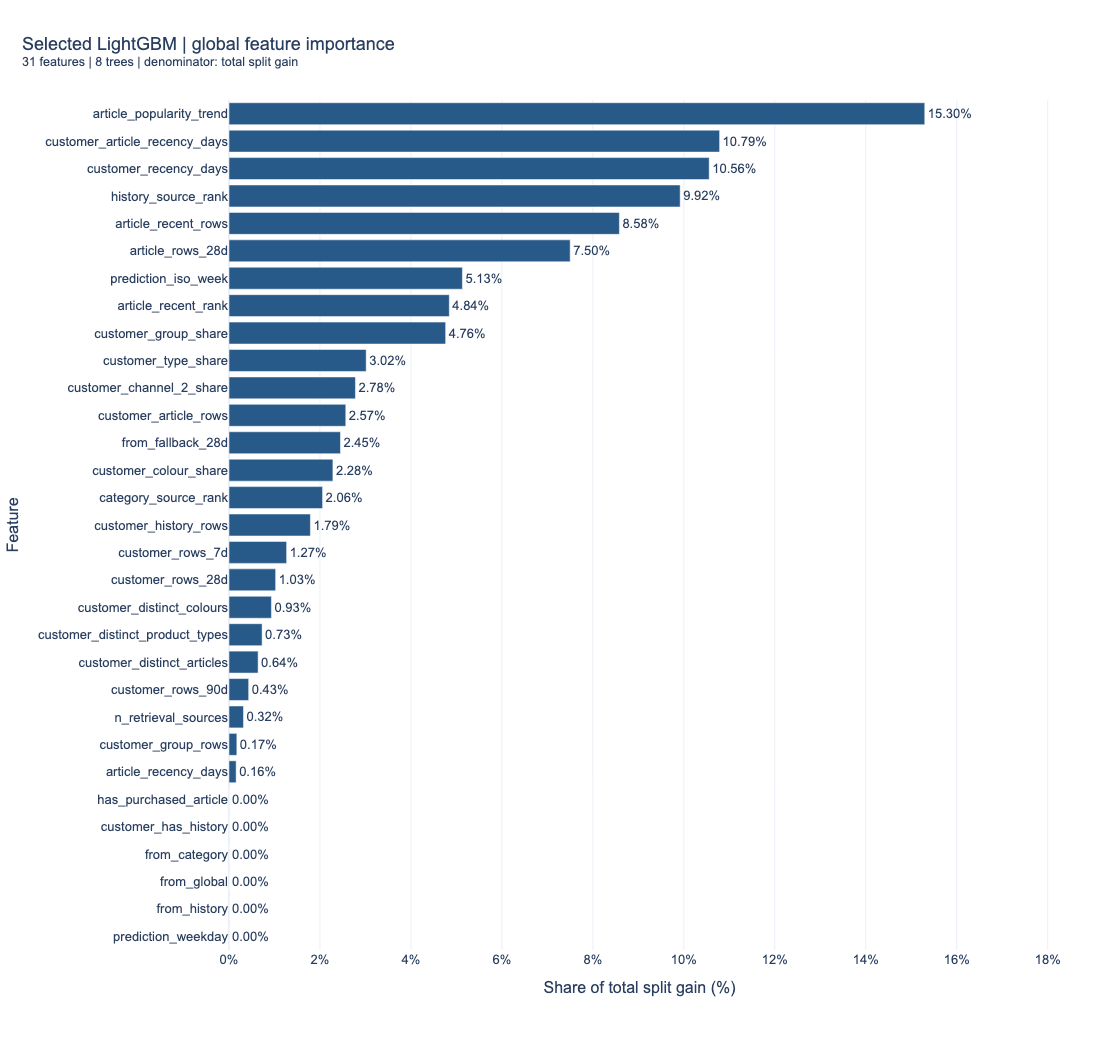

In [15]:
importance = pd.DataFrame(
    {
        "feature": model.feature_name(),
        "gain": model.feature_importance(
            importance_type="gain",
            iteration=-1,
        ),
        "split_count": model.feature_importance(
            importance_type="split",
            iteration=-1,
        ),
    }
)

assert len(importance) == 31
assert importance["feature"].is_unique
assert np.isfinite(importance["gain"]).all()
assert importance["gain"].ge(0).all()

total_gain = float(importance["gain"].sum())
assert total_gain > 0

importance["gain_share_pct"] = (
    100 * importance["gain"] / total_gain
)

assert np.isclose(
    importance["gain_share_pct"].sum(),
    100,
)

recorded_importance = pd.read_csv(
    MODEL_PATH.parent / "feature_importance.csv"
).set_index("feature")

np.testing.assert_allclose(
    importance["gain"].to_numpy(),
    recorded_importance.loc[
        importance["feature"], "gain"
    ].to_numpy(),
    rtol=1e-12,
    atol=1e-8,
)

importance = importance.sort_values(
    ["gain", "feature"],
    ascending=[False, True],
).reset_index(drop=True)

importance_path = DIAGNOSTIC_ROOT / "feature_importance.csv"
importance.to_csv(importance_path, index=False)

display(importance)

plot_data = importance.sort_values(
    "gain_share_pct",
    ascending=True,
)

fig = px.bar(
    plot_data,
    x="gain_share_pct",
    y="feature",
    orientation="h",
    text="gain_share_pct",
    hover_data={
        "gain": ":.2f",
        "split_count": True,
    },
    labels={
        "feature": "Feature",
        "gain_share_pct": "Share of total split gain (%)",
        "gain": "Total split gain",
        "split_count": "Number of splits",
    },
    title=(
        "Selected LightGBM | global feature importance"
        f"<br><sup>{model.num_feature()} features | "
        f"{model.num_trees()} trees | "
        "denominator: total split gain</sup>"
    ),
)

fig.update_traces(
    texttemplate="%{x:.2f}%",
    textposition="outside",
    cliponaxis=False,
)
fig.update_xaxes(
    range=[0, importance["gain_share_pct"].max() * 1.18],
    ticksuffix="%",
)
fig.update_yaxes(automargin=True)



figure_name = f"diagnostics_{candidate['method']}_gain"
show_figure(
    fig,
    PROJECT_ROOT,
    figure_name,
    height=1050,
)

manifest_path = (
    DIAGNOSTIC_ROOT / "feature_importance_manifest.json"
)
write_json(
    manifest_path,
    {
        "candidate": candidate,
        "importance_type": "gain",
        "total_gain": total_gain,
        "feature_count": len(importance),
        "tree_count": model.num_trees(),
    },
)

os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")
mlflow.set_tracking_uri((PROJECT_ROOT / "mlruns").as_uri())

with mlflow.start_run(run_id=candidate["mlflow_run_id"]):
    for path in [
        importance_path,
        manifest_path,
        PROJECT_ROOT / f"artifacts/figures/{figure_name}.png",
    ]:
        mlflow.log_artifact(
            str(path),
            artifact_path="stage8/feature_importance",
        )

## 2. Native SHAP explanations

Explain two recommendations for the same validation customer:
one with an observed target-week purchase and one without.

Select the first customer by sorted ID with between 1 and 11
purchased articles among their twelve recommendations. For each
outcome, select the highest-ranked recommendation.

This outcome-based selection is illustrative, not representative.
Absence of an observed purchase does not establish dislike.

Use the original pre-cutoff feature export and the selected model.
Native contributions must reconstruct the raw ranking score.
V1 and final-confirmation outcomes remain outside this analysis.

In [16]:
customer_scores = pd.read_csv(
    MODEL_PATH.parent / "customer_scores.csv",
    dtype={"customer_id": "string"},
)

eligible_buyers = customer_scores.loc[
    customer_scores["method"].eq(candidate["method"])
    & customer_scores["n_hits"].between(1, 11)
]

assert not eligible_buyers.empty

selected_customer = (
    eligible_buyers["customer_id"].sort_values().iloc[0]
)

recommendations = pd.read_csv(
    MODEL_PATH.parent / "recommendations.csv",
    dtype={"customer_id": "string", "article_id": "string"},
)

targets = pd.read_csv(
    DATA_ROOT / "validation/targets.csv",
    dtype="string",
)

relevant_articles = set(
    targets.loc[
        targets["customer_id"].eq(selected_customer),
        "article_id",
    ]
)

client_recommendations = (
    recommendations.loc[
        recommendations["customer_id"].eq(selected_customer)
    ]
    .sort_values(
        ["score", "article_id"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

assert len(client_recommendations) == 12

client_recommendations["rank"] = np.arange(1, 13)
client_recommendations["observed_purchase"] = (
    client_recommendations["article_id"].isin(relevant_articles)
)

examples = pd.concat(
    [
        client_recommendations.loc[
            client_recommendations["observed_purchase"]
        ].head(1).assign(case="Observed purchase"),
        client_recommendations.loc[
            ~client_recommendations["observed_purchase"]
        ].head(1).assign(case="No observed purchase"),
    ],
    ignore_index=True,
)

assert len(examples) == 2

display(
    examples[
        ["case", "article_id", "rank", "observed_purchase", "score"]
    ]
)

,case,article_id,rank,observed_purchase,score
0,Observed purchase,0918292001,9,True,0.199027
1,No observed purchase,0751471043,1,False,0.226804


In [17]:
import duckdb

feature_directory = (
    PROJECT_ROOT / candidate["validation"]["directory"]
)
validation_manifest = json.loads(
    (feature_directory / "manifest.json").read_text()
)

assert validation_manifest["fingerprint"] == (
    candidate["validation"]["fingerprint"]
)

paths = [
    str(feature_directory / part["file"])
    for part in validation_manifest["parts"]
]

pair_keys = ["customer_id", "article_id"]

with duckdb.connect(
    config={"threads": 2, "memory_limit": "512MB"}
) as connection:
    connection.register(
        "_shap_pairs",
        examples[pair_keys],
    )
    feature_rows = connection.execute(
        """
        SELECT f.*
        FROM read_parquet(?) AS f
        INNER JOIN _shap_pairs AS p
        USING (customer_id, article_id)
        """,
        [paths],
    ).df()

assert len(feature_rows) == len(examples)

explained = examples.merge(
    feature_rows,
    on=pair_keys,
    validate="one_to_one",
)

X_examples = explained[FEATURE_COLUMNS].astype("float32")

prediction_options = {
    "num_threads": 4,
    "validate_features": True,
}

raw_scores = model.predict(
    X_examples,
    raw_score=True,
    **prediction_options,
)

native_shap = np.asarray(
    model.predict(
        X_examples,
        pred_contrib=True,
        **prediction_options,
    )
)

assert native_shap.shape == (2, len(FEATURE_COLUMNS) + 1)
assert np.isfinite(native_shap).all()

base_values = native_shap[:, -1]
shap_values = native_shap[:, :-1]
reconstructed_scores = base_values + shap_values.sum(axis=1)

np.testing.assert_allclose(
    raw_scores,
    explained["score"],
    rtol=0,
    atol=1e-10,
)
np.testing.assert_allclose(
    reconstructed_scores,
    raw_scores,
    rtol=0,
    atol=1e-10,
)

explained["base_value"] = base_values
explained["raw_score"] = raw_scores
explained["reconstructed_score"] = reconstructed_scores

local_contributions = pd.concat(
    [
        pd.DataFrame(
            {
                "case": case,
                "feature": FEATURE_COLUMNS,
                "feature_value": X_examples.iloc[position].to_numpy(),
                "contribution": shap_values[position],
            }
        )
        for position, case in enumerate(explained["case"])
    ],
    ignore_index=True,
)

display(
    explained[
        [
            "case",
            "article_id",
            "rank",
            "base_value",
            "raw_score",
            "reconstructed_score",
        ]
    ]
)

,case,article_id,rank,base_value,raw_score,reconstructed_score
0,Observed purchase,0918292001,9,-0.026657,0.199027,0.199027
1,No observed purchase,0751471043,1,-0.026657,0.226804,0.226804


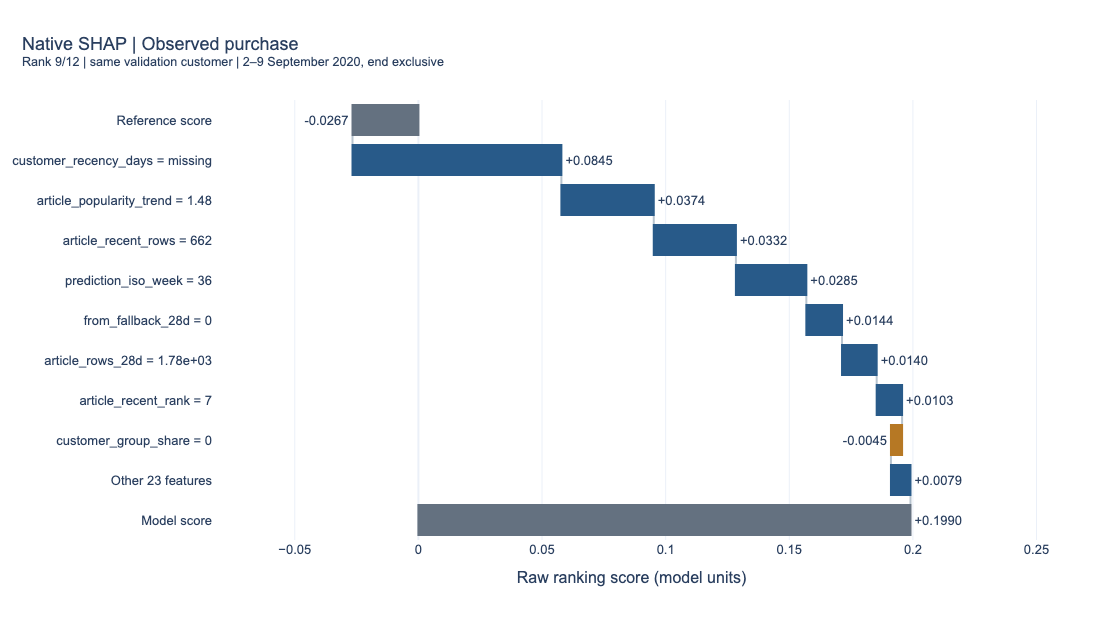

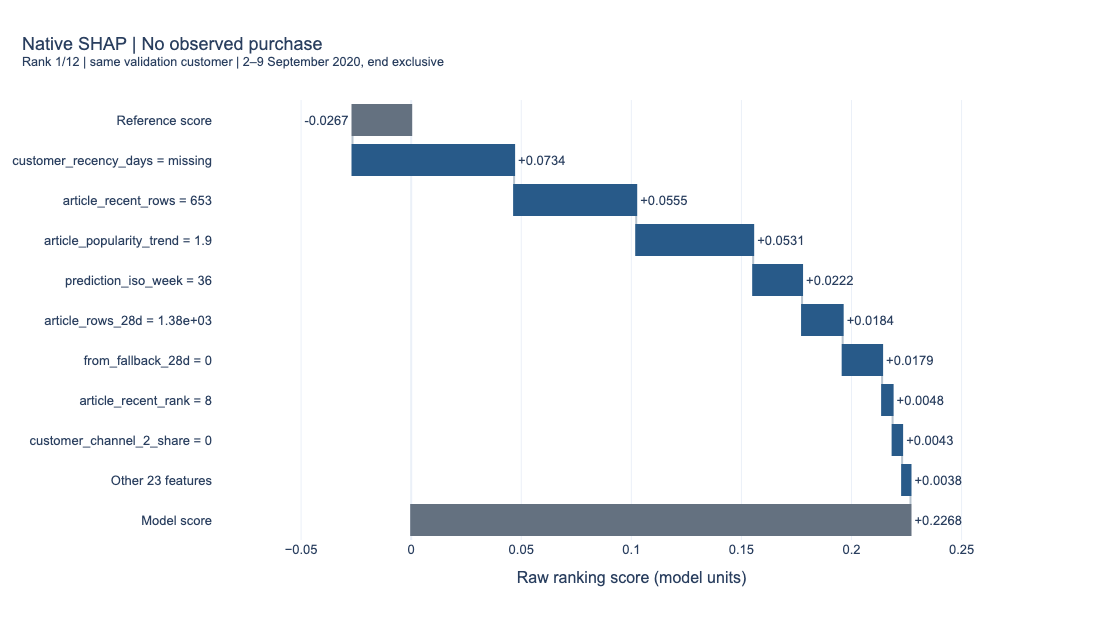

In [18]:
import plotly.graph_objects as go

examples_path = DIAGNOSTIC_ROOT / "shap_examples.csv"
contributions_path = DIAGNOSTIC_ROOT / "shap_contributions.csv"

explained.to_csv(examples_path, index=False)
local_contributions.to_csv(contributions_path, index=False)

shap_artifacts = [examples_path, contributions_path]

for position, example in enumerate(
    explained.itertuples(index=False)
):
    ranked = (
        local_contributions.loc[
            local_contributions["case"].eq(example.case)
        ]
        .assign(
            absolute_contribution=lambda frame: (
                frame["contribution"].abs()
            )
        )
        .sort_values(
            ["absolute_contribution", "feature"],
            ascending=[False, True],
        )
    )

    shown = ranked.head(8)
    other_contribution = float(
        ranked.iloc[8:]["contribution"].sum()
    )

    feature_labels = [
        (
            f"{row.feature} = {row.feature_value:.3g}"
            if pd.notna(row.feature_value)
            else f"{row.feature} = missing"
        )
        for row in shown.itertuples(index=False)
    ]

    labels = [
        "Reference score",
        *feature_labels,
        f"Other {len(ranked) - len(shown)} features",
        "Model score",
    ]
    values = [
        example.base_value,
        *shown["contribution"].tolist(),
        other_contribution,
        0,
    ]

    fig = go.Figure(
        go.Waterfall(
            orientation="h",
            measure=(
                ["absolute"]
                + ["relative"] * (len(shown) + 1)
                + ["total"]
            ),
            y=labels,
            x=values,
            text=(
                [f"{value:+.4f}" for value in values[:-1]]
                + [f"{example.raw_score:+.4f}"]
            ),
            textposition="outside",
            increasing={"marker": {"color": "#285A89"}},
            decreasing={"marker": {"color": "#B67824"}},
            totals={"marker": {"color": "#647180"}},
            connector={"line": {"color": "#B8C4CF"}},
        )
    )

    fig.update_layout(
        title=(
            f"Native SHAP | {example.case}"
            f"<br><sup>Rank {example.rank}/12 | "
            "same validation customer | "
            "2–9 September 2020, end exclusive</sup>"
        ),
        xaxis_title="Raw ranking score (model units)",
        showlegend=False,
    )
    fig.update_yaxes(
        autorange="reversed",
        automargin=True,
    )

    running_values = np.r_[
        0.0,
        np.cumsum(values[:-1]),
    ]
    axis_min = float(running_values.min())
    axis_max = float(running_values.max())
    padding = 0.25 * max(axis_max - axis_min, 1e-6)

    fig.update_xaxes(
        range=[axis_min - padding, axis_max + padding]
    )
    fig.update_traces(cliponaxis=False)

    figure_name = (
        f"diagnostics_{candidate['method']}_shap_{position + 1}"
    )
    show_figure(
        fig,
        PROJECT_ROOT,
        figure_name,
        height=640,
    )
    shap_artifacts.append(
        PROJECT_ROOT / f"artifacts/figures/{figure_name}.png"
    )

shap_manifest_path = DIAGNOSTIC_ROOT / "shap_manifest.json"
write_json(
    shap_manifest_path,
    {
        "model_sha256": candidate["model_sha256"],
        "validation_fingerprint": validation_manifest["fingerprint"],
        "feature_columns": FEATURE_COLUMNS,
        "explanation_space": "raw_ranking_score",
        "customers": 1,
        "examples": len(explained),
        "posthoc_outcome_based_selection": True,
        "selection_rule": (
            "First customer by ID with 1-11 top-12 hits; "
            "highest-ranked recommendation for each observed outcome"
        ),
    },
)
shap_artifacts.append(shap_manifest_path)

with mlflow.start_run(run_id=candidate["mlflow_run_id"]):
    for path in shap_artifacts:
        mlflow.log_artifact(
            str(path),
            artifact_path="stage8/native_shap",
        )

## 3. Controlled ranker feature ablations

Compare the full feature set with three explicitly defined removals:
recency in days, customer-category/colour affinities, and article
popularity measurements.

Retrain each variant on the same historical groups.
Keep candidate sets, target references and evaluation populations fixed.

Use 63 leaves, minimum 20 examples per leaf, and the same
full-reference NDCG@12 early-stopping rule with patience 50.
Do not repeat the hyperparameter grid search.

These ablations remove the listed ranker inputs. Retrieval features,
activity-window counts and candidate composition can retain related
information, so the comparison measures the additional utility of
the explicitly removed columns.

In [19]:
ABLATION_REMOVALS = {
    "without_recency_days": [
        "customer_recency_days",
        "article_recency_days",
        "customer_article_recency_days",
    ],
    "without_affinities": [
        "customer_group_rows",
        "customer_group_share",
        "customer_type_share",
        "customer_colour_share",
    ],
    "without_popularity": [
        "article_recent_rows",
        "article_recent_rank",
        "article_rows_28d",
        "article_popularity_trend",
    ],
}

assert all(
    set(removed).issubset(FEATURE_COLUMNS)
    for removed in ABLATION_REMOVALS.values()
)

ablation_features = {
    "full_control": FEATURE_COLUMNS.copy(),
    **{
        name: [
            feature
            for feature in FEATURE_COLUMNS
            if feature not in removed
        ]
        for name, removed in ABLATION_REMOVALS.items()
    },
}

ablation_plan = pd.DataFrame(
    [
        {
            "variant": name,
            "feature_count": len(columns),
            "removed_features": ABLATION_REMOVALS.get(name, []),
        }
        for name, columns in ablation_features.items()
    ]
)

write_json(
    DIAGNOSTIC_ROOT / "ablation_plan.json",
    {
        "reference_model_sha256": candidate["model_sha256"],
        "num_leaves": 63,
        "min_child_samples": 20,
        "retrain_each_variant": True,
        "fixed_candidate_sets": True,
        "early_stopping_rounds": 50,
        "feature_columns_by_variant": ablation_features,
    },
)

display(ablation_plan)

,variant,feature_count,removed_features
0,full_control,31,[]
1,without_recency_days,28,"[customer_recency_days, article_recency_days, ..."
2,without_affinities,27,"[customer_group_rows, customer_group_share, cu..."
3,without_popularity,27,"[article_recent_rows, article_recent_rank, art..."


In [20]:
import importlib
import inspect
import atelier_ai.workflow as workflow

workflow = importlib.reload(workflow)

signature = inspect.signature(
    workflow.fit_ranker_configuration
)

assert "feature_columns" in signature.parameters
assert signature.parameters["feature_columns"].default is None

print(signature)

(root, *, num_leaves, min_child_samples, method_name, output_subdirectory, feature_columns=None)


### 3.1. Fit the declared variants

Fit the full control first and verify that it reproduces the
selected stage-7 candidate's validation metrics and best iteration.

Then fit the three declared feature ablations using identical
training groups, candidates, complete references and stopping rules.

Each variant selects its own boosting iteration.
The original selected-candidate artifact remains the reference.

In [21]:
workflow = importlib.reload(workflow)

plan_path = DIAGNOSTIC_ROOT / "ablation_plan.json"
ablation_protocol = json.loads(plan_path.read_text())
plan_sha256 = file_sha256(plan_path)

assert ablation_protocol["reference_model_sha256"] == (
    candidate["model_sha256"]
)

variants = ablation_protocol["feature_columns_by_variant"]
assert next(iter(variants)) == "full_control"

ABLATION_ROOT = DATA_ROOT / "ablations"
ABLATION_ROOT.mkdir(parents=True, exist_ok=True)

ablation_rows = []
ablation_specs = []

metric_names = ["map_at_k", "recall_at_k", "ndcg_at_k"]

for variant, columns in variants.items():
    method_name = f"ablation_{variant}"
    print(f"\nRunning {variant}: {len(columns)} features", flush=True)

    spec, trial_comparison = workflow.fit_ranker_configuration(
        PROJECT_ROOT,
        num_leaves=ablation_protocol["num_leaves"],
        min_child_samples=ablation_protocol["min_child_samples"],
        method_name=method_name,
        output_subdirectory=f"ablations/{variant}",
        feature_columns=columns,
    )

    assert spec["feature_columns"] == columns
    assert spec["training"] == candidate["training"]
    assert spec["validation"] == candidate["validation"]

    if ablation_specs:
        assert spec["provenance"] == ablation_specs[0]["provenance"]

    metrics = trial_comparison.loc[
        trial_comparison["method"].eq(method_name)
    ].iloc[0].to_dict()

    assert metrics["recommendation_customers"] == 20_000
    assert metrics["evaluated_customers"] == (
        candidate["validation"]["buyers"]
    )
    assert metrics["target_pairs"] == (
        candidate["validation"]["target_pairs"]
    )

    if variant == "full_control":
        np.testing.assert_allclose(
            [metrics[name] for name in metric_names],
            [
                candidate["validation_metrics"][name]
                for name in metric_names
            ],
            rtol=0,
            atol=1e-12,
        )
        assert spec["best_iteration"] == (
            candidate["validation_best_iteration"]
        )
        print("Full control reproduces the stage-7 reference.")

    ablation_rows.append(
        {
            "variant": variant,
            "feature_count": len(columns),
            "best_iteration": spec["best_iteration"],
            "fit_seconds": spec["fit_seconds"],
            "score_seconds": spec["score_seconds"],
            "mlflow_run_id": spec["mlflow_run_id"],
            **metrics,
        }
    )
    ablation_specs.append(spec)

    pd.DataFrame(ablation_rows).to_csv(
        ABLATION_ROOT / "results.csv",
        index=False,
    )

assert len(ablation_rows) == 4
assert file_sha256(plan_path) == plan_sha256

write_json(
    ABLATION_ROOT / "manifest.json",
    {
        "ablation_complete": True,
        "ablation_plan_sha256": plan_sha256,
        "reference_candidate": candidate["method"],
        "final_selection_complete": False,
        "runs": ablation_specs,
    },
)

print("Completed the full control and three ablations.")


Running full_control: 31 features


/Users/oumar/Developer/portfolio/atelier-ai-project/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[25]	valid_0's ndcg_full_reference_at_12: 0.0394206
[50]	valid_0's ndcg_full_reference_at_12: 0.0388359
Early stopping, best iteration is:
[8]	valid_0's ndcg_full_reference_at_12: 0.0444959
Evaluated only: ndcg_full_reference_at_12
Full control reproduces the stage-7 reference.

Running without_recency_days: 28 features


/Users/oumar/Developer/portfolio/atelier-ai-project/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[25]	valid_0's ndcg_full_reference_at_12: 0.0365132
[50]	valid_0's ndcg_full_reference_at_12: 0.039187
Early stopping, best iteration is:
[6]	valid_0's ndcg_full_reference_at_12: 0.0396947
Evaluated only: ndcg_full_reference_at_12

Running without_affinities: 27 features


/Users/oumar/Developer/portfolio/atelier-ai-project/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[25]	valid_0's ndcg_full_reference_at_12: 0.0399651
[50]	valid_0's ndcg_full_reference_at_12: 0.0408696
[75]	valid_0's ndcg_full_reference_at_12: 0.0408903
[100]	valid_0's ndcg_full_reference_at_12: 0.0402067
Early stopping, best iteration is:
[69]	valid_0's ndcg_full_reference_at_12: 0.041939
Evaluated only: ndcg_full_reference_at_12

Running without_popularity: 27 features


/Users/oumar/Developer/portfolio/atelier-ai-project/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[25]	valid_0's ndcg_full_reference_at_12: 0.0367701
[50]	valid_0's ndcg_full_reference_at_12: 0.0362664
[75]	valid_0's ndcg_full_reference_at_12: 0.0365686
[100]	valid_0's ndcg_full_reference_at_12: 0.0353693
Early stopping, best iteration is:
[65]	valid_0's ndcg_full_reference_at_12: 0.0372329
Evaluated only: ndcg_full_reference_at_12
Completed the full control and three ablations.


### 3.2. Compare against the full control

One row represents one fitted variant.

Compute delta MAP@12 as:
variant MAP@12 minus full-control MAP@12.

All variants use the same validation buyers and complete targets.
Interpret differences as validation point estimates under the
declared fixed hyperparameters and candidate policy.

,variant,feature_count,best_iteration,map_at_k,delta_map,recall_at_k,ndcg_at_k,fit_seconds,score_seconds
0,full_control,31,8,0.032710,0.000000,0.059368,0.044496,29.476883,1.502417
1,without_recency_days,28,6,0.027859,-0.004851,0.055650,0.039695,27.114571,0.970118
2,without_affinities,27,69,0.028637,-0.004073,0.061341,0.041939,52.263300,5.141393
3,without_popularity,27,65,0.025210,-0.007500,0.054116,0.037233,42.382617,3.840342


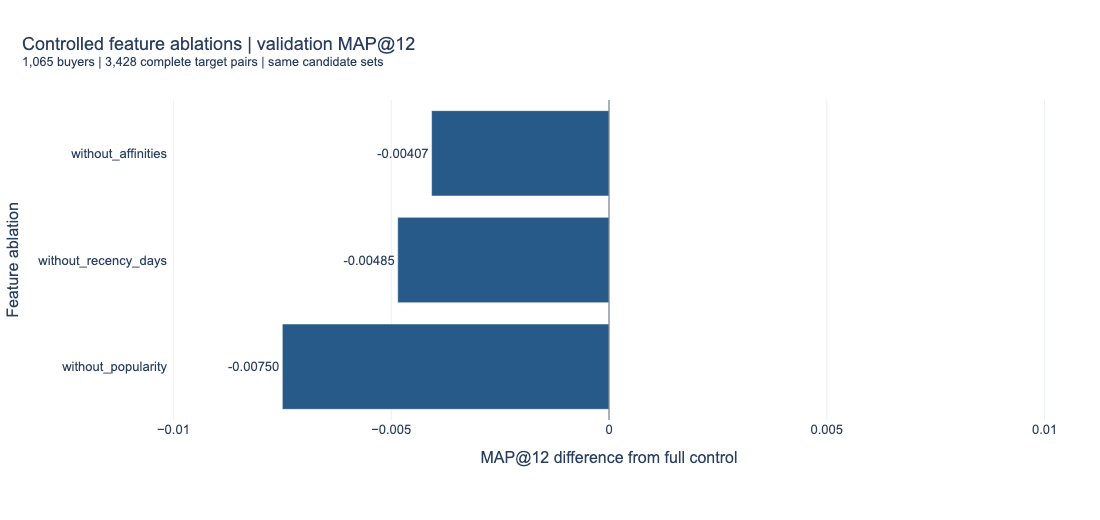

In [22]:
ablation_results = pd.read_csv(
    ABLATION_ROOT / "results.csv"
)

assert len(ablation_results) == 4
assert ablation_results["variant"].is_unique
assert ablation_results["candidate_coverage"].nunique() == 1

control_map = float(
    ablation_results.loc[
        ablation_results["variant"].eq("full_control"),
        "map_at_k",
    ].iloc[0]
)

ablation_results["delta_map"] = (
    ablation_results["map_at_k"] - control_map
)

display(
    ablation_results[
        [
            "variant",
            "feature_count",
            "best_iteration",
            "map_at_k",
            "delta_map",
            "recall_at_k",
            "ndcg_at_k",
            "fit_seconds",
            "score_seconds",
        ]
    ]
)

plot_data = (
    ablation_results.loc[
        ablation_results["variant"].ne("full_control")
    ]
    .sort_values("delta_map")
)

fig = px.bar(
    plot_data,
    x="delta_map",
    y="variant",
    orientation="h",
    text="delta_map",
    color_discrete_sequence=["#285A89"],
    labels={
        "variant": "Feature ablation",
        "delta_map": "MAP@12 difference from full control",
    },
    title=(
        "Controlled feature ablations | validation MAP@12"
        "<br><sup>1,065 buyers | 3,428 complete target pairs | "
        "same candidate sets</sup>"
    ),
)

fig.update_traces(
    texttemplate="%{x:+.5f}",
    textposition="outside",
    cliponaxis=False,
)
fig.add_vline(
    x=0,
    line_color="#647180",
    line_width=1,
)
fig.update_yaxes(automargin=True)

extent = max(
    float(plot_data["delta_map"].abs().max()),
    1e-4,
)
fig.update_xaxes(range=[-1.35 * extent, 1.35 * extent])

figure_name = "ablation_validation_delta_map"
show_figure(fig, PROJECT_ROOT, figure_name, height=520)

results_path = ABLATION_ROOT / "results.csv"
ablation_results.to_csv(results_path, index=False)

for spec in ablation_specs:
    with mlflow.start_run(run_id=spec["mlflow_run_id"]):
        for path in [
            results_path,
            plan_path,
            PROJECT_ROOT / f"artifacts/figures/{figure_name}.png",
        ]:
            mlflow.log_artifact(
                str(path),
                artifact_path="stage8/ablation_comparison",
            )

### 3.3. Ablation findings

All three declared removals reduce validation MAP@12.
Removing article-popularity measurements produces the largest drop.

The full control reproduces the stage-7 candidate exactly.
Keep the complete model as the reference for subsequent diagnostics;
final selection remains pending.

## 4. Locate missed target purchases

Separate target articles absent from candidates from target articles
retrieved but not recommended in the top twelve.

Report two different populations:
- distinct customer-article targets: denominator 3,428;
- validation buyers: denominator 1,065.

Customers without target purchases are outside these counts.
All 20,000 cohort customers still receive recommendations.

In [23]:
pair_keys = ["customer_id", "article_id"]

validation_targets = pd.read_csv(
    DATA_ROOT / "validation/targets.csv",
    dtype="string",
)

recommended_pairs = pd.read_csv(
    MODEL_PATH.parent / "recommendations.csv",
    usecols=pair_keys,
    dtype="string",
)

assert not validation_targets.duplicated(pair_keys).any()
assert not recommended_pairs.duplicated(pair_keys).any()
assert len(validation_targets) == candidate["validation"]["target_pairs"]

feature_directory = (
    PROJECT_ROOT / candidate["validation"]["directory"]
)
feature_manifest = json.loads(
    (feature_directory / "manifest.json").read_text()
)

assert feature_manifest["fingerprint"] == (
    candidate["validation"]["fingerprint"]
)

feature_paths = [
    str(feature_directory / part["file"])
    for part in feature_manifest["parts"]
]

with duckdb.connect(
    config={"threads": 2, "memory_limit": "512MB"}
) as connection:
    connection.register("_validation_targets", validation_targets)

    candidate_matches = connection.execute(
        """
        SELECT f.customer_id, f.article_id
        FROM read_parquet(?) AS f
        INNER JOIN _validation_targets AS t
        USING (customer_id, article_id)
        """,
        [feature_paths],
    ).df()

assert not candidate_matches.duplicated(pair_keys).any()

target_audit = (
    validation_targets.merge(
        candidate_matches.assign(in_candidates=True),
        on=pair_keys,
        how="left",
        validate="one_to_one",
    )
    .merge(
        recommended_pairs.assign(in_top12=True),
        on=pair_keys,
        how="left",
        validate="one_to_one",
    )
)

for column in ["in_candidates", "in_top12"]:
    target_audit[column] = (
        target_audit[column].fillna(False).astype(bool)
    )

assert len(target_audit) == len(validation_targets)
assert (
    ~target_audit["in_top12"] | target_audit["in_candidates"]
).all()

target_order = [
    "Outside candidates",
    "Candidate, outside top 12",
    "In top 12",
]

target_audit["outcome"] = np.select(
    [
        ~target_audit["in_candidates"],
        target_audit["in_top12"],
    ],
    [target_order[0], target_order[2]],
    default=target_order[1],
)

buyer_audit = (
    target_audit.groupby("customer_id")
    .agg(
        target_articles=("article_id", "size"),
        candidate_targets=("in_candidates", "sum"),
        top12_hits=("in_top12", "sum"),
    )
    .reset_index()
)

assert len(buyer_audit) == candidate["validation"]["buyers"]

buyer_order = [
    "No target in candidates",
    "Targets in candidates, no top-12 hit",
    "At least one top-12 hit",
]

buyer_audit["outcome"] = np.select(
    [
        buyer_audit["candidate_targets"].eq(0),
        buyer_audit["top12_hits"].eq(0),
    ],
    [buyer_order[0], buyer_order[1]],
    default=buyer_order[2],
)

comparison = pd.read_csv(MODEL_PATH.parent / "comparison.csv")
model_summary = comparison.loc[
    comparison["method"].eq(candidate["method"])
].iloc[0]

assert target_audit["in_top12"].sum() == (
    model_summary["retrieved_target_pairs"]
)
np.testing.assert_allclose(
    target_audit["in_candidates"].mean(),
    model_summary["candidate_coverage"],
    rtol=0,
    atol=1e-12,
)
np.testing.assert_allclose(
    target_audit["in_top12"].mean(),
    model_summary["micro_recall_at_k"],
    rtol=0,
    atol=1e-12,
)

target_audit.to_csv(
    DIAGNOSTIC_ROOT / "target_error_audit.csv",
    index=False,
)
buyer_audit.to_csv(
    DIAGNOSTIC_ROOT / "buyer_error_audit.csv",
    index=False,
)

,outcome,count,denominator,share_pct
0,Outside candidates,2754,3428,80.338390
1,"Candidate, outside top 12",535,3428,15.606768
2,In top 12,139,3428,4.054842


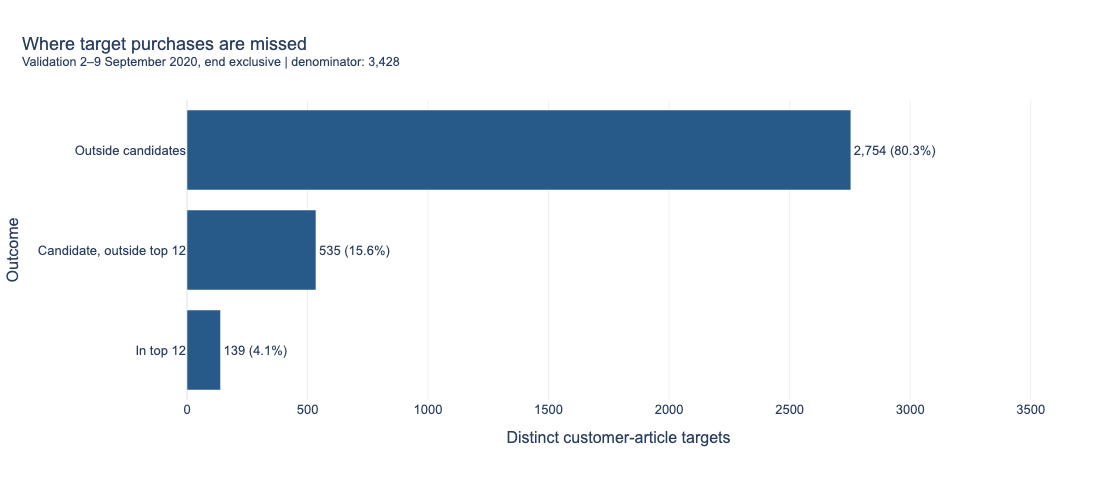

,outcome,count,denominator,share_pct
0,No target in candidates,624,1065,58.591549
1,"Targets in candidates, no top-12 hit",327,1065,30.704225
2,At least one top-12 hit,114,1065,10.704225


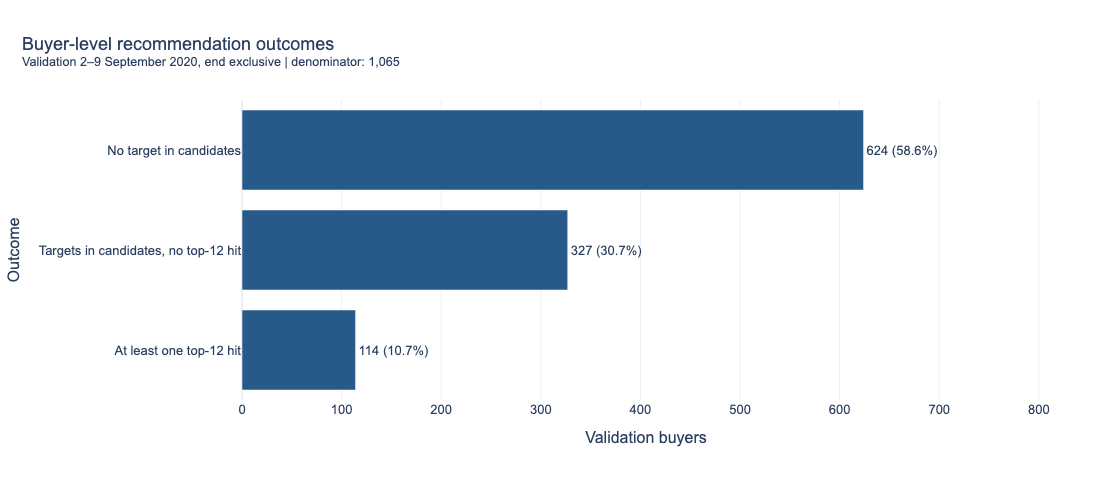

In [24]:
def summarise_outcomes(frame, order, *, name, title, unit):
    summary = (
        frame["outcome"]
        .value_counts()
        .reindex(order, fill_value=0)
        .rename_axis("outcome")
        .reset_index(name="count")
    )

    summary["denominator"] = len(frame)
    summary["share_pct"] = (
        100 * summary["count"] / summary["denominator"]
    )
    summary["label"] = [
        f"{count:,} ({share:.1f}%)"
        for count, share in zip(
            summary["count"],
            summary["share_pct"],
        )
    ]

    assert summary["count"].sum() == len(frame)
    assert np.isclose(summary["share_pct"].sum(), 100)

    display(
        summary[
            ["outcome", "count", "denominator", "share_pct"]
        ]
    )

    fig = px.bar(
        summary,
        x="count",
        y="outcome",
        orientation="h",
        text="label",
        labels={"outcome": "Outcome", "count": unit},
        color_discrete_sequence=["#285A89"],
        title=(
            f"{title}"
            f"<br><sup>Validation 2–9 September 2020, end exclusive"
            f" | denominator: {len(frame):,}</sup>"
        ),
    )
    fig.update_traces(
        textposition="outside",
        cliponaxis=False,
    )
    fig.update_yaxes(
        autorange="reversed",
        automargin=True,
    )
    fig.update_xaxes(
        range=[0, max(1, summary["count"].max()) * 1.30]
    )

    figure_name = f"diagnostics_{candidate['method']}_{name}"
    show_figure(fig, PROJECT_ROOT, figure_name, height=500)

    table_path = DIAGNOSTIC_ROOT / f"{name}.csv"
    summary.to_csv(table_path, index=False)

    return summary, [
        table_path,
        PROJECT_ROOT / f"artifacts/figures/{figure_name}.png",
    ]


target_counts, target_artifacts = summarise_outcomes(
    target_audit,
    target_order,
    name="target_outcomes",
    title="Where target purchases are missed",
    unit="Distinct customer-article targets",
)

buyer_counts, buyer_artifacts = summarise_outcomes(
    buyer_audit,
    buyer_order,
    name="buyer_outcomes",
    title="Buyer-level recommendation outcomes",
    unit="Validation buyers",
)

error_manifest_path = DIAGNOSTIC_ROOT / "error_analysis_manifest.json"
write_json(
    error_manifest_path,
    {
        "model_sha256": candidate["model_sha256"],
        "validation": candidate["validation"],
        "target_pair_denominator": len(target_audit),
        "buyer_denominator": len(buyer_audit),
    },
)

with mlflow.start_run(run_id=candidate["mlflow_run_id"]):
    for path in [
        DIAGNOSTIC_ROOT / "target_error_audit.csv",
        DIAGNOSTIC_ROOT / "buyer_error_audit.csv",
        error_manifest_path,
        *target_artifacts,
        *buyer_artifacts,
    ]:
        mlflow.log_artifact(
            str(path),
            artifact_path="stage8/error_analysis",
        )

### 4.1. Findings and illustrative cases

Of 3,428 complete target pairs:
- 2,754 are outside the candidate sets;
- 535 are candidates but outside the top twelve;
- 139 are recommended.

Among 1,065 buyers, 624 have no target in candidates,
327 have candidate targets but no top-12 hit,
and 114 have at least one top-12 hit.

Illustrative cases are the first buyer by sorted customer ID
within each outcome in buyer_error_audit.csv:

| Case | Target articles | Candidate targets | Top-12 hits | Interpretation |
|---|---:|---:|---:|---|
| No target in candidates | 4 | 0 | 0 | Ranking cannot recover these targets under the fixed candidate set |
| Candidate targets, no hit | 4 | 2 | 0 | Relevant candidates exist but none reaches the top twelve |
| Partial success | 6 | 2 | 1 | One purchase is recovered, while five remain missed |

These cases illustrate failure modes; they are not a representative sample.

## 5. Performance by observed history

Define segments from the 180-day history before 2020-09-02:
purchase-row activity and distinct-article richness.

Compare the selected model with the best validation baseline
on the same buyers within every segment.

Report recipient counts, buyer counts and complete target counts.
Nonbuyers retain missing AP values and are excluded from MAP.
Buyers with AP=0 remain included.

In [25]:
with duckdb.connect(
    config={"threads": 2, "memory_limit": "512MB"}
) as connection:
    profiles = connection.execute(
        """
        SELECT DISTINCT
            customer_id,
            customer_history_rows,
            customer_distinct_articles
        FROM read_parquet(?)
        ORDER BY customer_id
        """,
        [feature_paths],
    ).df()

profile_columns = [
    "customer_history_rows",
    "customer_distinct_articles",
]

cohort_ids = pd.read_csv(
    DATA_ROOT / "cohort.csv",
    dtype="string",
)["customer_id"]

assert len(profiles) == 20_000
assert profiles["customer_id"].is_unique
assert set(profiles["customer_id"]) == set(cohort_ids)
assert profiles[profile_columns].notna().all().all()
assert profiles[profile_columns].ge(0).all().all()
assert profiles["customer_distinct_articles"].le(
    profiles["customer_history_rows"]
).all()

profiles["activity_segment"] = pd.cut(
    profiles["customer_history_rows"],
    bins=[-1, 0, 10, 50, np.inf],
    labels=[
        "No observed history",
        "1-10 purchase rows",
        "11-50 purchase rows",
        "51+ purchase rows",
    ],
)

profiles["richness_segment"] = pd.cut(
    profiles["customer_distinct_articles"],
    bins=[-1, 0, 5, 20, np.inf],
    labels=[
        "No observed history",
        "1-5 distinct articles",
        "6-20 distinct articles",
        "21+ distinct articles",
    ],
)

assert profiles[
    ["activity_segment", "richness_segment"]
].notna().all().all()

In [26]:
baseline_results = pd.read_csv(
    DATA_ROOT / "validation/baselines.csv"
)
baseline_row = baseline_results.sort_values(
    ["map_at_k", "method"],
    ascending=[False, True],
).iloc[0]
baseline_name = baseline_row["method"]

all_customer_scores = pd.read_csv(
    MODEL_PATH.parent / "customer_scores.csv",
    dtype={"customer_id": "string"},
)

selected_scores = (
    all_customer_scores.loc[
        all_customer_scores["method"].eq(candidate["method"]),
        ["customer_id", "n_target_articles", "ap_at_k"],
    ]
    .rename(columns={"ap_at_k": "model_ap"})
)

baseline_scores = (
    all_customer_scores.loc[
        all_customer_scores["method"].eq(baseline_name),
        ["customer_id", "ap_at_k"],
    ]
    .rename(columns={"ap_at_k": "baseline_ap"})
)

paired_scores = selected_scores.merge(
    baseline_scores,
    on="customer_id",
    validate="one_to_one",
)

assert len(selected_scores) == len(baseline_scores) == (
    len(paired_scores)
) == candidate["validation"]["buyers"]

assert paired_scores[
    ["model_ap", "baseline_ap"]
].notna().all().all()

segment_panel = profiles.merge(
    paired_scores,
    on="customer_id",
    how="left",
    validate="one_to_one",
)
segment_panel["is_buyer"] = segment_panel["model_ap"].notna()

assert len(segment_panel) == 20_000
assert segment_panel["is_buyer"].sum() == 1_065

paired_scores_path = DIAGNOSTIC_ROOT / "paired_customer_scores.csv"
panel_path = DIAGNOSTIC_ROOT / "validation_customer_segments.csv"

paired_scores.to_csv(paired_scores_path, index=False)
segment_panel.to_csv(panel_path, index=False)

print("Baseline:", baseline_name)
print("Recipients:", len(segment_panel))
print("Evaluated buyers:", segment_panel["is_buyer"].sum())

Baseline: recent_purchases_180d
Recipients: 20000
Evaluated buyers: 1065


,activity_segment,recipients,buyers,target_pairs,excluded_share_pct,model_map,baseline_map,delta_map
0,No observed history,9350,185,555,98.021390,0.013674,0.004979,0.008695
1,1-10 purchase rows,7265,374,992,94.852030,0.030460,0.024315,0.006146
2,11-50 purchase rows,3180,435,1494,86.320755,0.038960,0.033296,0.005664
3,51+ purchase rows,205,71,387,65.365854,0.055869,0.036620,0.019249


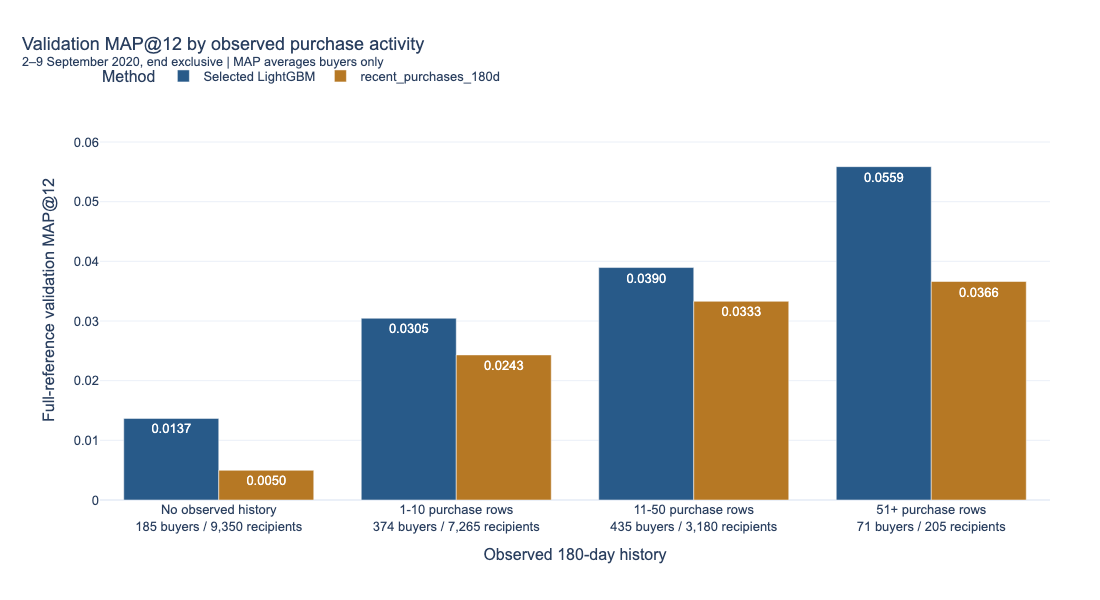

,richness_segment,recipients,buyers,target_pairs,excluded_share_pct,model_map,baseline_map,delta_map
0,No observed history,9350,185,555,98.021390,0.013674,0.004979,0.008695
1,1-5 distinct articles,5271,221,567,95.807247,0.029556,0.024016,0.005541
2,6-20 distinct articles,4259,431,1304,89.880254,0.037585,0.030603,0.006981
3,21+ distinct articles,1120,228,1002,79.642857,0.041999,0.033685,0.008314


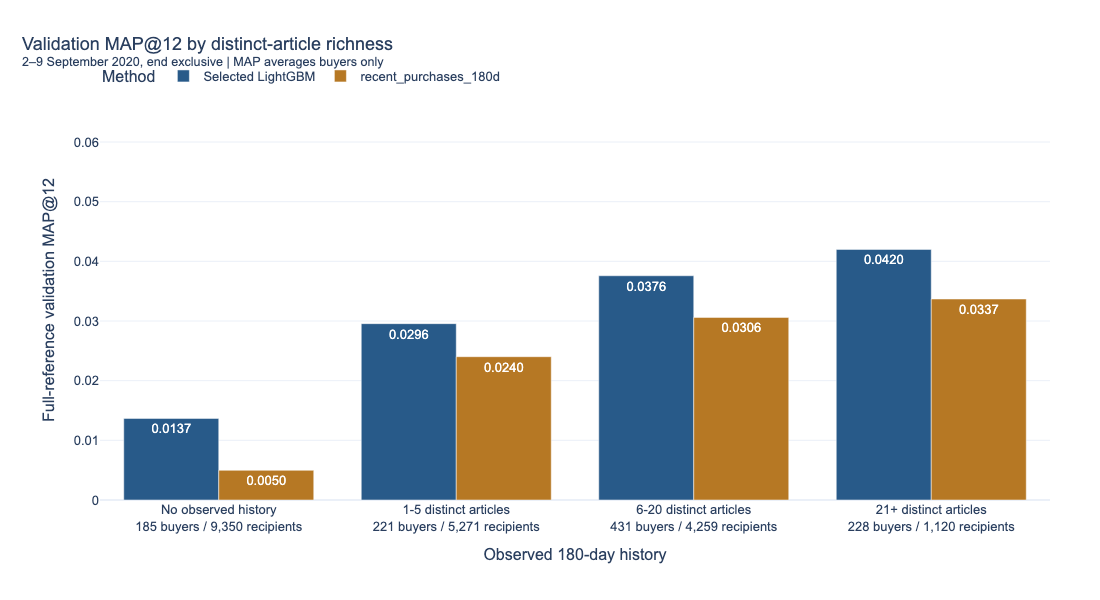

In [27]:
def make_segment_summary(panel, segment):
    summary = (
        panel.groupby(segment, observed=False)
        .agg(
            recipients=("customer_id", "size"),
            buyers=("model_ap", "count"),
            target_pairs=("n_target_articles", "sum"),
            model_map=("model_ap", "mean"),
            baseline_map=("baseline_ap", "mean"),
        )
        .reset_index()
    )

    summary["target_pairs"] = summary["target_pairs"].astype(int)
    summary["excluded_share_pct"] = (
        100
        * (summary["recipients"] - summary["buyers"])
        / summary["recipients"].replace(0, np.nan)
    )
    summary["delta_map"] = (
        summary["model_map"] - summary["baseline_map"]
    )
    summary["segment_label"] = [
        f"{label}<br>{int(buyers):,} buyers / {int(recipients):,} recipients"
        for label, buyers, recipients in zip(
            summary[segment],
            summary["buyers"],
            summary["recipients"],
        )
    ]

    assert summary["recipients"].sum() == 20_000
    assert summary["buyers"].sum() == 1_065
    assert summary["target_pairs"].sum() == 3_428

    return summary


segment_specs = {
    "activity_segment": (
        "activity_segments",
        "Validation MAP@12 by observed purchase activity",
    ),
    "richness_segment": (
        "richness_segments",
        "Validation MAP@12 by distinct-article richness",
    ),
}

segment_summaries = {
    segment: make_segment_summary(segment_panel, segment)
    for segment in segment_specs
}

common_y_max = 1.20 * max(
    summary[["model_map", "baseline_map"]].max().max()
    for summary in segment_summaries.values()
)

segment_artifacts = [paired_scores_path, panel_path]

for segment, summary in segment_summaries.items():
    name, title = segment_specs[segment]
    eligible = summary["buyers"].gt(0)

    for metric, expected in [
        ("model_map", candidate["validation_metrics"]["map_at_k"]),
        ("baseline_map", baseline_row["map_at_k"]),
    ]:
        np.testing.assert_allclose(
            np.average(
                summary.loc[eligible, metric],
                weights=summary.loc[eligible, "buyers"],
            ),
            expected,
            rtol=0,
            atol=1e-12,
        )

    display(
        summary[
            [
                segment,
                "recipients",
                "buyers",
                "target_pairs",
                "excluded_share_pct",
                "model_map",
                "baseline_map",
                "delta_map",
            ]
        ]
    )

    table_path = DIAGNOSTIC_ROOT / f"{name}.csv"
    summary.to_csv(table_path, index=False)

    chart_frame = summary.rename(
        columns={
            "model_map": "Selected LightGBM",
            "baseline_map": baseline_name,
        }
    )

    fig = px.bar(
        chart_frame,
        x="segment_label",
        y=["Selected LightGBM", baseline_name],
        barmode="group",
        text_auto=".4f",
        hover_data=["buyers", "recipients", "target_pairs"],
        color_discrete_map={
            "Selected LightGBM": "#285A89",
            baseline_name: "#B67824",
        },
        labels={
            "segment_label": "Observed 180-day history",
            "value": "Full-reference validation MAP@12",
            "variable": "Method",
        },
        title=(
            f"{title}"
            "<br><sup>2–9 September 2020, end exclusive | "
            "MAP averages buyers only</sup>"
        ),
    )
    fig.update_yaxes(range=[0, common_y_max])

    figure_name = f"diagnostics_{candidate['method']}_{name}"
    show_figure(fig, PROJECT_ROOT, figure_name, height=600)

    segment_artifacts.extend(
        [
            table_path,
            PROJECT_ROOT / f"artifacts/figures/{figure_name}.png",
        ]
    )

segment_manifest_path = DIAGNOSTIC_ROOT / "segmentation_manifest.json"
write_json(
    segment_manifest_path,
    {
        "model_sha256": candidate["model_sha256"],
        "baseline": baseline_name,
        "validation": candidate["validation"],
        "history_days": 180,
        "recipients": len(segment_panel),
        "buyers": len(paired_scores),
        "activity_ranges": ["0", "1-10", "11-50", "51+"],
        "distinct_article_ranges": ["0", "1-5", "6-20", "21+"],
    },
)
segment_artifacts.append(segment_manifest_path)

with mlflow.start_run(run_id=candidate["mlflow_run_id"]):
    for path in segment_artifacts:
        mlflow.log_artifact(
            str(path),
            artifact_path="stage8/segments",
        )

## 6. Paired customer bootstrap

We estimate uncertainty around validation MAP@12 and its difference
between the selected LightGBM model and the strongest baseline.

The resampling unit is an eligible target buyer. Each sampled buyer
retains both methods' AP@12 values, including zero scores.

We draw 5,000 samples with replacement, each containing the same number
of buyers as the original evaluation. We report percentile 95% intervals.

These are exploratory intervals conditional on the fitted methods and
the validation week. They do not account for model selection,
retraining variability, or variation across future weeks.

In [28]:
segmentation_manifest = json.loads(
    (DIAGNOSTIC_ROOT / "segmentation_manifest.json").read_text()
)

assert (
    segmentation_manifest["model_sha256"]
    == candidate["model_sha256"]
    == file_sha256(MODEL_PATH)
)

bootstrap_baseline = segmentation_manifest["baseline"]
paired_scores_path = DIAGNOSTIC_ROOT / "paired_customer_scores.csv"

bootstrap_scores = (
    pd.read_csv(
        paired_scores_path,
        dtype={"customer_id": "string"},
    )
    .sort_values("customer_id")
    .reset_index(drop=True)
)

baseline_results = pd.read_csv(
    DATA_ROOT / "validation/baselines.csv"
)
baseline_reference = baseline_results.loc[
    baseline_results["method"].eq(bootstrap_baseline)
]

assert len(baseline_reference) == 1
assert bootstrap_scores["customer_id"].notna().all()
assert bootstrap_scores["customer_id"].is_unique
assert len(bootstrap_scores) == candidate["validation"]["buyers"]
assert bootstrap_scores["n_target_articles"].gt(0).all()
assert (
    bootstrap_scores["n_target_articles"].sum()
    == candidate["validation"]["target_pairs"]
)

ap_pairs = bootstrap_scores[
    ["model_ap", "baseline_ap"]
].to_numpy(dtype=float)

assert np.isfinite(ap_pairs).all()
assert ((ap_pairs >= 0) & (ap_pairs <= 1)).all()

observed_maps = ap_pairs.mean(axis=0)
observed_delta = observed_maps[0] - observed_maps[1]

np.testing.assert_allclose(
    observed_maps,
    [
        candidate["validation_metrics"]["map_at_k"],
        baseline_reference.iloc[0]["map_at_k"],
    ],
    rtol=0,
    atol=1e-12,
)

print("Baseline:", bootstrap_baseline)
print("Evaluated buyers:", len(ap_pairs))
print(f"Observed MAP@12 difference: {observed_delta:.6f}")

Baseline: recent_purchases_180d
Evaluated buyers: 1065
Observed MAP@12 difference: 0.007265


In [29]:
N_BOOTSTRAP = 5_000
BOOTSTRAP_SEED = 42
CONFIDENCE_LEVEL = 0.95

rng = np.random.default_rng(BOOTSTRAP_SEED)
n_buyers = len(ap_pairs)

sampled_indices = rng.integers(
    low=0,
    high=n_buyers,
    size=(N_BOOTSTRAP, n_buyers),
)

bootstrap_maps = ap_pairs[sampled_indices].mean(axis=1)
del sampled_indices

bootstrap_samples = pd.DataFrame(
    bootstrap_maps,
    columns=["model_map", "baseline_map"],
)

bootstrap_samples["delta_map"] = (
    bootstrap_samples["model_map"]
    - bootstrap_samples["baseline_map"]
)

alpha = 1 - CONFIDENCE_LEVEL
interval_bounds = bootstrap_samples.quantile(
    [alpha / 2, 1 - alpha / 2]
)

bootstrap_summary = pd.DataFrame(
    {
        "metric": bootstrap_samples.columns,
        "observed": [
            observed_maps[0],
            observed_maps[1],
            observed_delta,
        ],
        "ci_lower": interval_bounds.iloc[0].to_numpy(),
        "ci_upper": interval_bounds.iloc[1].to_numpy(),
        "evaluated_buyers": n_buyers,
        "bootstrap_resamples": N_BOOTSTRAP,
    }
)

display(bootstrap_summary)

bootstrap_samples_path = DIAGNOSTIC_ROOT / "bootstrap_samples.csv"
bootstrap_summary_path = DIAGNOSTIC_ROOT / "bootstrap_summary.csv"

bootstrap_samples.to_csv(bootstrap_samples_path, index=False)
bootstrap_summary.to_csv(bootstrap_summary_path, index=False)

,metric,observed,ci_lower,ci_upper,evaluated_buyers,bootstrap_resamples
0,model_map,0.032710,0.024545,0.041608,1065,5000
1,baseline_map,0.025445,0.018660,0.033233,1065,5000
2,delta_map,0.007265,0.002316,0.012509,1065,5000


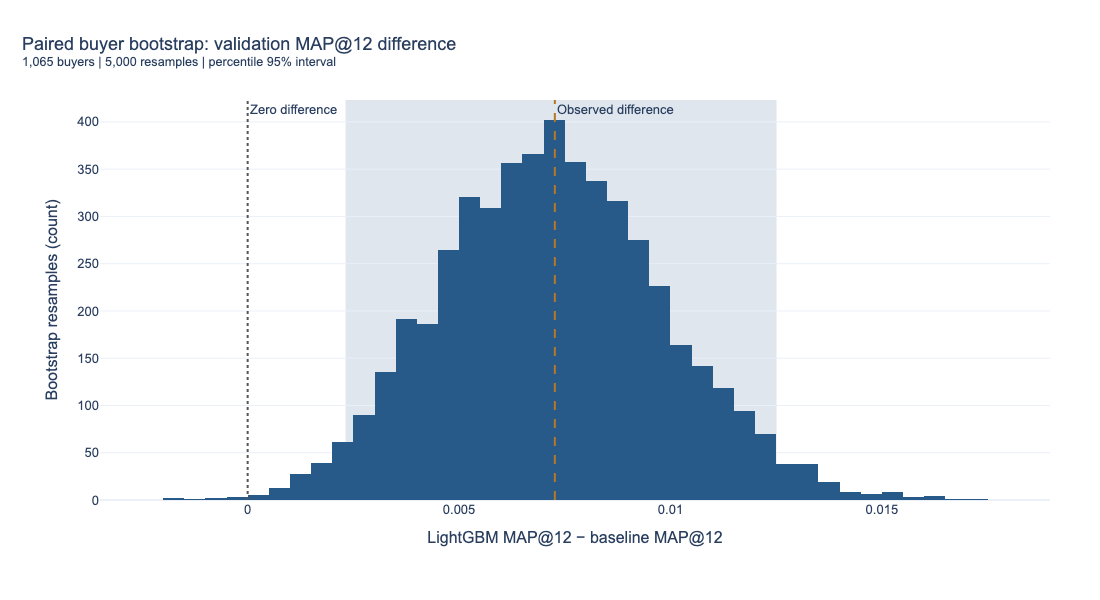

In [30]:
delta_interval = bootstrap_summary.set_index("metric").loc[
    "delta_map"
]
ci_lower = float(delta_interval["ci_lower"])
ci_upper = float(delta_interval["ci_upper"])

fig = px.histogram(
    bootstrap_samples,
    x="delta_map",
    nbins=50,
    color_discrete_sequence=["#285A89"],
    labels={
        "delta_map": "LightGBM MAP@12 − baseline MAP@12",
    },
    title=(
        "Paired buyer bootstrap: validation MAP@12 difference"
        f"<br><sup>{n_buyers:,} buyers | "
        f"{N_BOOTSTRAP:,} resamples | "
        "percentile 95% interval</sup>"
    ),
)

fig.add_vrect(
    x0=ci_lower,
    x1=ci_upper,
    fillcolor="#285A89",
    opacity=0.15,
    line_width=0,
    layer="below",
)

fig.add_vline(
    x=0,
    line_color="#555555",
    line_dash="dot",
    annotation_text="Zero difference",
    annotation_position="top right",
)

fig.add_vline(
    x=observed_delta,
    line_color="#B67824",
    line_dash="dash",
    annotation_text="Observed difference",
    annotation_position="top right",
)

x_min = min(0.0, bootstrap_samples["delta_map"].min())
x_max = max(0.0, bootstrap_samples["delta_map"].max())
padding = 0.08 * max(x_max - x_min, 1e-6)

fig.update_xaxes(range=[x_min - padding, x_max + padding])
fig.update_yaxes(title_text="Bootstrap resamples (count)")

figure_name = f"diagnostics_{candidate['method']}_paired_bootstrap"
show_figure(fig, PROJECT_ROOT, figure_name, height=600)

bootstrap_manifest_path = DIAGNOSTIC_ROOT / "bootstrap_manifest.json"

write_json(
    bootstrap_manifest_path,
    {
        "model_sha256": candidate["model_sha256"],
        "baseline": bootstrap_baseline,
        "validation": candidate["validation"],
        "paired_scores_file": str(
            paired_scores_path.relative_to(PROJECT_ROOT)
        ),
        "paired_scores_sha256": file_sha256(paired_scores_path),
        "resampling_unit": "eligible target buyer",
        "paired": True,
        "includes_zero_ap": True,
        "evaluated_buyers": n_buyers,
        "bootstrap_resamples": N_BOOTSTRAP,
        "seed": BOOTSTRAP_SEED,
        "confidence_level": CONFIDENCE_LEVEL,
        "interval_method": "percentile",
        "scope": (
            "Exploratory validation analysis conditional on fixed "
            "fitted methods and the observed validation week."
        ),
    },
)

bootstrap_artifacts = [
    bootstrap_samples_path,
    bootstrap_summary_path,
    bootstrap_manifest_path,
    PROJECT_ROOT / f"artifacts/figures/{figure_name}.png",
]

with mlflow.start_run(run_id=candidate["mlflow_run_id"]):
    for path in bootstrap_artifacts:
        mlflow.log_artifact(
            str(path),
            artifact_path="stage8/uncertainty",
        )

### Bootstrap findings

The observed MAP@12 difference is +0.007265, with a paired percentile
95% interval of [0.002316, 0.012509] across 1,065 eligible validation buyers.

This supports a positive difference on the observed validation week.
The interval remains exploratory: it conditions on fixed fitted methods
and does not account for model selection or variation across future weeks.

## 7. Local batch timings

We measure one local inference pass for all 20,000 recipients at the
validation cutoff, using 300 candidates per recipient.

We separate historical-context construction, candidate retrieval,
feature lookups, batch feature construction, model scoring, and top-12
selection. Candidate features are processed in batches of 500 customers.

The model is already loaded. Training, result persistence, plotting,
and evaluation are excluded from the timed stages. Feature-construction
checks remain included.

These single-pass measurements describe this local batch workload.
They are not API latency measurements or repeated performance benchmarks.

In [31]:
from hashlib import sha256
from time import perf_counter
import platform

from atelier_ai.workflow import build_context
from atelier_ai.recommendation_features import (
    retrieve_candidates,
    prepare_feature_tables,
    build_checked_feature_batch,
)

TIMING_BATCH_CUSTOMERS = 500

feature_directory = PROJECT_ROOT / candidate["validation"]["directory"]
feature_manifest = json.loads(
    (feature_directory / "manifest.json").read_text()
)

timing_ids = pd.Index(
    pd.read_csv(
        feature_directory / "cohort.csv",
        dtype="string",
    )["customer_id"]
)
timing_cutoff = pd.Timestamp(candidate["validation"]["cutoff"])

assert len(timing_ids) == 20_000
assert timing_ids.is_unique and not timing_ids.isna().any()
assert feature_manifest["fingerprint"] == (
    candidate["validation"]["fingerprint"]
)
assert sha256(
    ("\n".join(timing_ids) + "\n").encode()
).hexdigest() == candidate["validation"]["cohort_sha256"]

assert file_sha256(MODEL_PATH) == candidate["model_sha256"]
timing_model = lgb.Booster(model_file=str(MODEL_PATH))
assert timing_model.feature_name() == FEATURE_COLUMNS


def make_timing_features(batch_ids, pools, tables):
    pairs = pd.DataFrame(
        [
            (customer_id, article_id, timing_cutoff)
            for customer_id in batch_ids
            for article_id in pools[customer_id]
        ],
        columns=["customer_id", "article_id", "cutoff"],
    )
    batch = build_checked_feature_batch(pairs, tables)

    return (
        batch[["customer_id", "article_id"]].copy(),
        batch[FEATURE_COLUMNS].astype("float32"),
    )


def select_timing_top12(keys, scores):
    return (
        keys.assign(score=scores)
        .sort_values(
            ["customer_id", "score", "article_id"],
            ascending=[True, False, True],
        )
        .groupby("customer_id", sort=False)
        .head(12)
    )

In [32]:
timing_records = []


def timed(stage, operation, *args, **kwargs):
    started = perf_counter()
    result = operation(*args, **kwargs)
    timing_records.append(
        {
            "stage": stage,
            "seconds": perf_counter() - started,
        }
    )
    return result


timing_context = timed(
    "Historical context",
    build_context,
    PROJECT_ROOT,
    timing_ids,
    timing_cutoff,
)

timing_pools, timing_memberships, _, timing_audit = timed(
    "Candidate retrieval",
    retrieve_candidates,
    timing_ids,
    timing_context,
)

# Verify the complete ordered candidate lists outside the timed stages.
pool_digest = sha256()
for customer_id in timing_ids:
    payload = json.dumps(
        [str(customer_id), timing_pools[customer_id]],
        sort_keys=True,
        separators=(",", ":"),
        ensure_ascii=False,
    )
    pool_digest.update((payload + "\n").encode())

assert pool_digest.hexdigest() == feature_manifest["candidate_sha256"]

timing_tables = timed(
    "Feature lookups",
    prepare_feature_tables,
    timing_ids,
    timing_context,
    timing_memberships,
)

timing_top_parts = []
timing_candidate_rows = 0

for offset in range(0, len(timing_ids), TIMING_BATCH_CUSTOMERS):
    batch_ids = timing_ids[offset:offset + TIMING_BATCH_CUSTOMERS]

    batch_keys, batch_features = timed(
        "Batch features",
        make_timing_features,
        batch_ids,
        timing_pools,
        timing_tables,
    )

    batch_scores = timed(
        "Model scoring",
        timing_model.predict,
        batch_features,
        num_threads=4,
    )

    timing_top_parts.append(
        timed(
            "Top-12 selection",
            select_timing_top12,
            batch_keys,
            batch_scores,
        )
    )
    timing_candidate_rows += len(batch_keys)

    del batch_keys, batch_features, batch_scores

    if len(timing_top_parts) % 10 == 0:
        print(f"Processed recipients: {offset + len(batch_ids):,}")

timing_top = pd.concat(timing_top_parts, ignore_index=True)
expected_top = pd.read_csv(
    MODEL_PATH.parent / "recommendations.csv",
    dtype={"customer_id": "string", "article_id": "string"},
)

sort_columns = ["customer_id", "score", "article_id"]
sort_directions = [True, False, True]

timing_top = timing_top.sort_values(
    sort_columns, ascending=sort_directions
).reset_index(drop=True)
expected_top = expected_top.sort_values(
    sort_columns, ascending=sort_directions
).reset_index(drop=True)

assert timing_candidate_rows == candidate["validation"]["candidate_rows"]
assert len(timing_top) == len(timing_ids) * 12

pd.testing.assert_frame_equal(
    timing_top[["customer_id", "article_id"]],
    expected_top[["customer_id", "article_id"]],
    check_dtype=False,
)
np.testing.assert_allclose(
    timing_top["score"],
    expected_top["score"],
    rtol=0,
    atol=1e-12,
)

timing_calls = pd.DataFrame(timing_records)
timing_summary = (
    timing_calls.groupby("stage", sort=False)
    .agg(
        seconds=("seconds", "sum"),
        calls=("seconds", "size"),
    )
    .reset_index()
)

display(timing_summary)
print("Saved recommendations reproduced successfully.")

Processed recipients: 5,000
Processed recipients: 10,000
Processed recipients: 15,000
Processed recipients: 20,000


,stage,seconds,calls
0,Historical context,0.580211,1
1,Candidate retrieval,15.565338,1
2,Feature lookups,0.369806,1
3,Batch features,39.525935,40
4,Model scoring,0.902460,40
5,Top-12 selection,2.126891,40


Saved recommendations reproduced successfully.


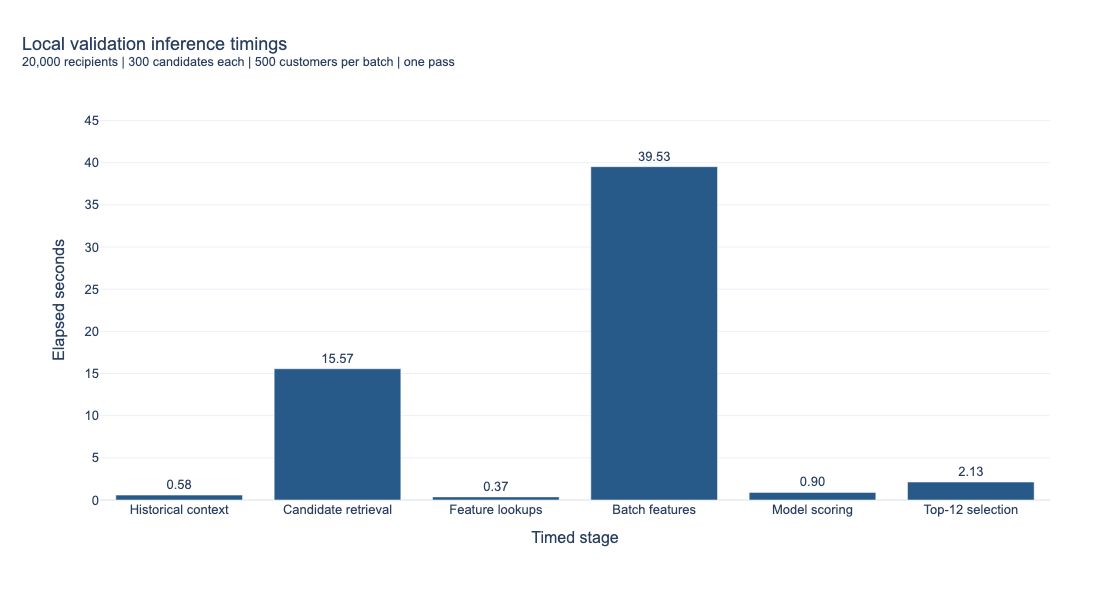

In [33]:
fig = px.bar(
    timing_summary,
    x="stage",
    y="seconds",
    text_auto=".2f",
    hover_data=["calls"],
    color_discrete_sequence=["#285A89"],
    labels={
        "stage": "Timed stage",
        "seconds": "Elapsed seconds",
        "calls": "Timed calls",
    },
    title=(
        "Local validation inference timings"
        "<br><sup>20,000 recipients | 300 candidates each | "
        "500 customers per batch | one pass</sup>"
    ),
)

fig.update_xaxes(tickangle=0)
fig.update_yaxes(
    range=[0, 1.20 * timing_summary["seconds"].max()]
)
fig.update_traces(textposition="outside", cliponaxis=False)

figure_name = f"diagnostics_{candidate['method']}_batch_timings"
show_figure(fig, PROJECT_ROOT, figure_name, height=600)

timing_calls_path = DIAGNOSTIC_ROOT / "timing_calls.csv"
timing_summary_path = DIAGNOSTIC_ROOT / "timing_summary.csv"
timing_manifest_path = DIAGNOSTIC_ROOT / "timing_manifest.json"

timing_calls.to_csv(timing_calls_path, index=False)
timing_summary.to_csv(timing_summary_path, index=False)

write_json(
    timing_manifest_path,
    {
        "measured_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
        "model_sha256": candidate["model_sha256"],
        "validation": candidate["validation"],
        "candidate_sha256": pool_digest.hexdigest(),
        "recipients": len(timing_ids),
        "candidate_rows": timing_candidate_rows,
        "batch_customers": TIMING_BATCH_CUSTOMERS,
        "prediction_threads": 4,
        "full_passes": 1,
        "units": "elapsed seconds",
        "model_loading_included": False,
        "recommendations_match_saved": True,
        "cache_state": "Uncontrolled; not a cold-start benchmark",
        "platform": platform.platform(),
        "python": platform.python_version(),
        "lightgbm": lgb.__version__,
        "pandas": pd.__version__,
        "source_sha256": {
            name: file_sha256(PROJECT_ROOT / "src/atelier_ai" / name)
            for name in [
                "workflow.py",
                "preparation.py",
                "historical_contexts.py",
                "recommendation_features.py",
            ]
        },
    },
)

with mlflow.start_run(run_id=candidate["mlflow_run_id"]):
    for path in [
        timing_calls_path,
        timing_summary_path,
        timing_manifest_path,
        PROJECT_ROOT / f"artifacts/figures/{figure_name}.png",
    ]:
        mlflow.log_artifact(
            str(path),
            artifact_path="stage8/timings",
        )

### Timing findings

The timed stages sum to 59.07 seconds for 20,000 recipients and
6,000,000 candidate pairs in one local pass.

Batch feature construction takes 39.53 seconds, candidate retrieval
15.57 seconds, and model scoring 0.90 seconds. Input preparation
dominates this measured workload.

These measurements exclude model loading, training, persistence,
plotting, and evaluation. They do not establish API latency.

## 8. Freeze the V1 selection

We retain the 63-leaf / minimum-20 LightGBM configuration, all 31
features, and the existing candidate policy. Selection follows
full-reference validation MAP@12.

The final refit will use eight boosting iterations, selected during
validation. It will include historical training and validation groups,
with each group's features computed strictly before its own cutoff.
Training eligibility remains unchanged.

The refit will not use early stopping or V1 targets. V1 results will
be reported without changing this frozen configuration.

Catalogue coverage and broad-category diversity are lower than for
the recent-purchases baseline. These remain explicit tradeoffs.

Intermediate V1 is retrospective because of prior development
exposure. Final confirmation remains reserved for the later frozen
LightGBM/PyTorch comparison.

In [34]:
from atelier_ai.workflow import load_protocol

protocol = load_protocol(PROJECT_ROOT)

selection_model = lgb.Booster(model_file=str(MODEL_PATH))
refit_iterations = int(candidate["validation_best_iteration"])

assert file_sha256(MODEL_PATH) == candidate["model_sha256"]
assert selection_model.num_trees() == refit_iterations == 8
assert selection_model.feature_name() == FEATURE_COLUMNS

for split in ["training", "validation"]:
    current_index = json.loads(
        (DATA_ROOT / f"{split}.json").read_text()
    )
    assert current_index == candidate[split]

refit_parameters = {
    **candidate["parameters"],
    "n_estimators": refit_iterations,
}

selection_manifest = json.loads(
    (MODEL_PATH.parent / "manifest.json").read_text()
)

retrieval_keys = [
    "history_limit",
    "global_limit_7d",
    "preferred_product_types",
    "per_preferred_type",
    "fallback_days",
    "candidate_budget",
]

evidence_paths = [
    DATA_ROOT / "ranker_search/selected_candidate.json",
    DATA_ROOT / "ranker_search/results.csv",
    MODEL_PATH.parent / "comparison.csv",
    DATA_ROOT / "ablations/results.csv",
    DIAGNOSTIC_ROOT / "bootstrap_summary.csv",
    DIAGNOSTIC_ROOT / "segmentation_manifest.json",
    DIAGNOSTIC_ROOT / "timing_manifest.json",
]

selection_decision = {
    "schema_version": 1,
    "status": "frozen_for_v1_refit",
    "method": candidate["method"],
    "selection_metric": candidate["selection_metric"],
    "selection_model_file": candidate["model_file"],
    "selection_model_sha256": candidate["model_sha256"],
    "selection_mlflow_run_id": candidate["mlflow_run_id"],
    "feature_columns": list(FEATURE_COLUMNS),
    "refit_parameters": refit_parameters,
    "retrieval": {
        key: selection_manifest["provenance"][key]
        for key in retrieval_keys
    },
    "training": candidate["training"],
    "validation": candidate["validation"],
    "refit_protocol": {
        "training_cutoffs": [
            export["cutoff"]
            for export in candidate["training"]["exports"]
        ] + [candidate["validation"]["cutoff"]],
        "group_unit": "customer and prediction cutoff",
        "group_eligibility": "complete groups with both label classes",
        "early_stopping": False,
        "uses_v1_targets": False,
    },
    "v1_evaluation": {
        "start_inclusive": str(
            protocol["v1_evaluation_start"].date()
        ),
        "end_exclusive": str(
            protocol["confirmation_start"].date()
        ),
        "k": 12,
        "full_reference_targets": True,
        "target_metric_population": "all target buyers",
        "change_configuration_after_results": False,
        "prior_development_exposure": True,
    },
    "confirmation_reserved": True,
    "temporal_config_sha256": file_sha256(
        PROJECT_ROOT / "configs/temporal.yaml"
    ),
    "evidence_sha256": {
        str(path.relative_to(PROJECT_ROOT)): file_sha256(path)
        for path in evidence_paths
    },
}

In [35]:
FINAL_SELECTION_PATH = DATA_ROOT / "final_selection.json"

if FINAL_SELECTION_PATH.exists():
    frozen_selection = json.loads(
        FINAL_SELECTION_PATH.read_text()
    )
    assert frozen_selection["decision"] == selection_decision, (
        "A different frozen selection already exists. "
        "Review the difference before changing the decision."
    )
else:
    frozen_selection = {
        "frozen_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
        "decision": selection_decision,
    }
    write_json(FINAL_SELECTION_PATH, frozen_selection)

with mlflow.start_run(run_id=candidate["mlflow_run_id"]):
    mlflow.log_artifact(
        str(FINAL_SELECTION_PATH),
        artifact_path="stage8/selection",
    )

display(
    pd.Series(
        {
            "status": frozen_selection["decision"]["status"],
            "method": selection_decision["method"],
            "features": len(selection_decision["feature_columns"]),
            "refit_iterations": refit_parameters["n_estimators"],
            "refit_training_weeks": len(
                selection_decision["refit_protocol"]["training_cutoffs"]
            ),
            "early_stopping": False,
            "confirmation_reserved": True,
        }
    )
)

status                         frozen_for_v1_refit
method                   lightgbm_leaves_63_min_20
features                                        31
refit_iterations                                 8
refit_training_weeks                             7
early_stopping                               False
confirmation_reserved                         True
dtype: object

## 9. Prepare the final training dataset

The final fitting dataset combines the six historical training weeks
with the former validation week at cutoff 2020-09-02.

Each example retains its original prediction cutoff and historical
features. The added week's targets end at 2020-09-09, before any
intermediate V1 target purchase can enter fitting.

The former validation week is exported explicitly as training data.
Complete customer-cutoff groups are eligible for fitting only when
they contain both positive and negative candidate labels.

All groups remain documented in the audit. This fitting filter will
not restrict the population used for V1 evaluation.

In [36]:
import duckdb

from atelier_ai.workflow import export_cutoff
from atelier_ai.ranking_data import (
    inspect_training_groups,
    load_eligible_training_rows,
    prepare_ranker_inputs,
)

FINAL_SELECTION_PATH = DATA_ROOT / "final_selection.json"

frozen = json.loads(
    FINAL_SELECTION_PATH.read_text()
)["decision"]

assert frozen["status"] == "frozen_for_v1_refit"
assert frozen["feature_columns"] == FEATURE_COLUMNS
assert file_sha256(
    PROJECT_ROOT / "configs/temporal.yaml"
) == frozen["temporal_config_sha256"]

refit_boundary = pd.Timestamp(
    frozen["v1_evaluation"]["start_inclusive"]
)
added_cutoff = pd.Timestamp(frozen["validation"]["cutoff"])

refit_ids = pd.Index(
    pd.read_csv(
        DATA_ROOT / "cohort.csv",
        dtype="string",
    )["customer_id"]
)

assert refit_ids.is_unique and not refit_ids.isna().any()
assert sha256(
    ("\n".join(refit_ids) + "\n").encode()
).hexdigest() == frozen["training"]["cohort_sha256"]

assert added_cutoff + pd.Timedelta(days=7) == refit_boundary

added_export, _, _, _, _ = export_cutoff(
    PROJECT_ROOT,
    refit_ids,
    added_cutoff,
    split="training",
    notebook_path=(
        PROJECT_ROOT / "notebooks/07_model_diagnostics.ipynb"
    ),
)

original_validation_manifest = json.loads(
    (
        PROJECT_ROOT
        / frozen["validation"]["directory"]
        / "manifest.json"
    ).read_text()
)

assert added_export["manifest"]["candidate_sha256"] == (
    original_validation_manifest["candidate_sha256"]
)
assert added_export["manifest"]["feature_columns"] == (
    frozen["feature_columns"]
)

added_paths = [
    str(added_export["directory"] / part["file"])
    for part in added_export["manifest"]["parts"]
]

Verified feature partitions: 5; customers: 2,500
Verified feature partitions: 10; customers: 5,000
Verified feature partitions: 15; customers: 7,500
Verified feature partitions: 20; customers: 10,000
Verified feature partitions: 25; customers: 12,500
Verified feature partitions: 30; customers: 15,000
Verified feature partitions: 35; customers: 17,500
Verified feature partitions: 40; customers: 20,000


In [37]:
added_audit = inspect_training_groups(
    added_paths,
    validation_cutoff=refit_boundary,
    candidates_per_group=frozen["retrieval"]["candidate_budget"],
    dataset_split="training",
)

added_rows = load_eligible_training_rows(
    added_paths,
    added_audit,
    dataset_split="training",
)

historical_rows_path = DATA_ROOT / "training/rows.parquet"

assert file_sha256(historical_rows_path) == (
    frozen["training"]["row_sha256"]
)

with duckdb.connect(
    config={"threads": 2, "memory_limit": "512MB"}
) as connection:
    historical_rows = connection.execute(
        "SELECT * FROM read_parquet(?)",
        [str(historical_rows_path)],
    ).df()

    historical_audit = connection.execute(
        "SELECT * FROM read_parquet(?)",
        [str(DATA_ROOT / "training/group_audit.parquet")],
    ).df()

assert len(historical_rows) == frozen["training"]["training_rows"]
assert len(historical_audit) == frozen["training"]["raw_groups"]

refit_rows = pd.concat(
    [historical_rows, added_rows],
    ignore_index=True,
)

refit_audit = pd.concat(
    [historical_audit, added_audit],
    ignore_index=True,
).sort_values(["cutoff", "customer_id"]).reset_index(drop=True)

expected_cutoffs = pd.DatetimeIndex(
    frozen["refit_protocol"]["training_cutoffs"]
)

assert set(refit_audit["cutoff"]) == set(expected_cutoffs)
assert not refit_audit.duplicated(
    ["cutoff", "customer_id"]
).any()
assert len(refit_audit) == len(refit_ids) * len(expected_cutoffs)

assert (
    refit_rows["cutoff"] + pd.Timedelta(days=7)
).le(refit_boundary).all()

refit_inputs = prepare_ranker_inputs(
    refit_rows,
    validation_cutoff=refit_boundary,
    feature_columns=frozen["feature_columns"],
)

assert len(refit_inputs["groups"]) == refit_audit["eligible"].sum()
assert refit_inputs["groups"].sum() == len(refit_rows)
assert (
    refit_inputs["groups"]
    == frozen["retrieval"]["candidate_budget"]
).all()

del historical_rows, added_rows

,cutoff,audited_groups,eligible_groups,fitting_rows,positive_candidate_pairs,origin
0,2020-07-22,20000,434,130200,650,Historical training
1,2020-07-29,20000,458,137400,687,Historical training
2,2020-08-05,20000,418,125400,620,Historical training
3,2020-08-12,20000,380,114000,584,Historical training
4,2020-08-19,20000,377,113100,574,Historical training
5,2020-08-26,20000,466,139800,672,Historical training
6,2020-09-02,20000,441,132300,674,Former validation


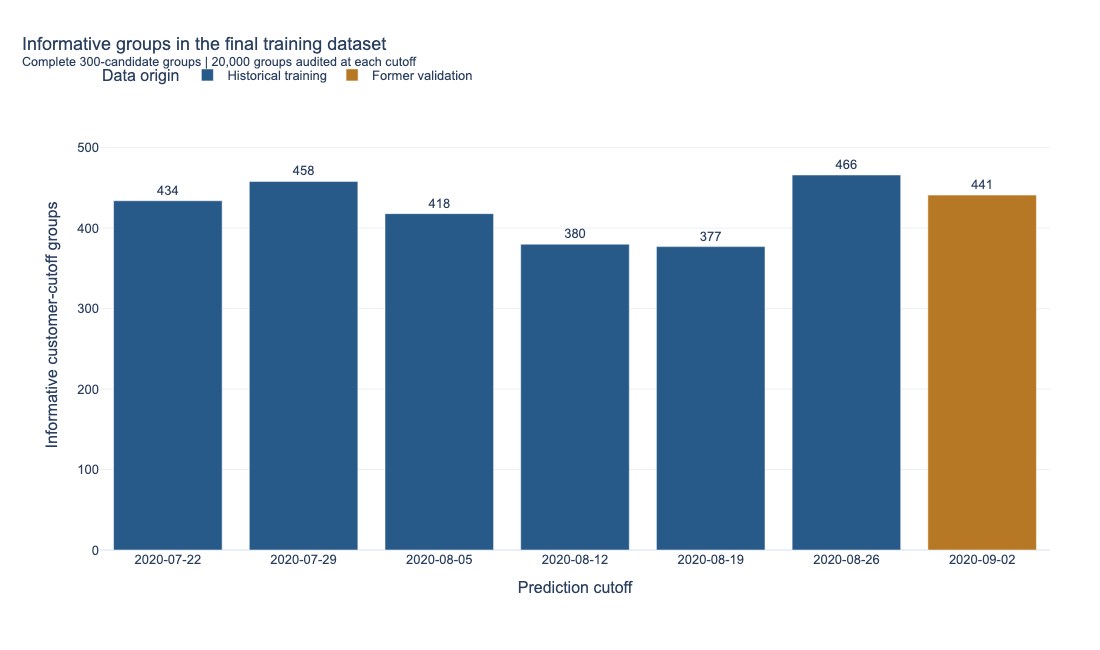

In [38]:
refit_summary = (
    refit_audit.assign(
        fitting_rows=np.where(
            refit_audit["eligible"],
            refit_audit["candidate_rows"],
            0,
        ),
        fitting_positives=np.where(
            refit_audit["eligible"],
            refit_audit["positive_rows"],
            0,
        ),
    )
    .groupby("cutoff", as_index=False)
    .agg(
        audited_groups=("customer_id", "size"),
        eligible_groups=("eligible", "sum"),
        fitting_rows=("fitting_rows", "sum"),
        positive_candidate_pairs=("fitting_positives", "sum"),
    )
)

refit_summary["origin"] = np.where(
    refit_summary["cutoff"].eq(added_cutoff),
    "Former validation",
    "Historical training",
)
refit_summary["cutoff_label"] = (
    refit_summary["cutoff"].dt.strftime("%Y-%m-%d")
)

assert refit_summary["audited_groups"].eq(len(refit_ids)).all()
assert refit_summary["fitting_rows"].sum() == len(refit_rows)
assert refit_summary["positive_candidate_pairs"].sum() == (
    int(refit_inputs["y"].sum())
)

display(refit_summary.drop(columns="cutoff_label"))

fig = px.bar(
    refit_summary,
    x="cutoff_label",
    y="eligible_groups",
    color="origin",
    text_auto=True,
    hover_data=[
        "audited_groups",
        "fitting_rows",
        "positive_candidate_pairs",
    ],
    color_discrete_map={
        "Historical training": "#285A89",
        "Former validation": "#B67824",
    },
    labels={
        "cutoff_label": "Prediction cutoff",
        "eligible_groups": "Informative customer-cutoff groups",
        "origin": "Data origin",
    },
    title=(
        "Informative groups in the final training dataset"
        "<br><sup>Complete 300-candidate groups | "
        "20,000 groups audited at each cutoff</sup>"
    ),
)

fig.update_xaxes(type="category", tickangle=0)
fig.update_yaxes(
    range=[0, 1.20 * refit_summary["eligible_groups"].max()]
)
fig.update_traces(textposition="outside", cliponaxis=False)

figure_name = "final_training_informative_groups"
show_figure(fig, PROJECT_ROOT, figure_name, height=650)

In [39]:
FINAL_TRAINING_ROOT = DATA_ROOT / "final_training"
FINAL_TRAINING_ROOT.mkdir(parents=True, exist_ok=True)

with duckdb.connect(
    config={"threads": 2, "memory_limit": "512MB"}
) as connection:
    for frame, name in [
        (refit_rows, "rows"),
        (refit_audit, "group_audit"),
        (refit_inputs["group_index"], "groups"),
    ]:
        connection.register("_refit_export", frame)
        connection.sql(
            "SELECT * FROM _refit_export"
        ).write_parquet(
            str(FINAL_TRAINING_ROOT / f"{name}.parquet"),
            compression="zstd",
        )
        connection.unregister("_refit_export")

summary_path = FINAL_TRAINING_ROOT / "summary.csv"
refit_summary.to_csv(summary_path, index=False)

manifest_path = FINAL_TRAINING_ROOT / "manifest.json"

write_json(
    manifest_path,
    {
        "status": "complete",
        "dataset_role": "final_model_fitting",
        "selection_sha256": file_sha256(FINAL_SELECTION_PATH),
        "historical_rows_sha256": frozen["training"]["row_sha256"],
        "added_export": {
            "directory": str(
                added_export["directory"].relative_to(PROJECT_ROOT)
            ),
            "fingerprint": added_export["manifest"]["fingerprint"],
        },
        "training_cutoffs": frozen["refit_protocol"]["training_cutoffs"],
        "feature_columns": frozen["feature_columns"],
        "audited_groups": len(refit_audit),
        "eligible_groups": len(refit_inputs["groups"]),
        "training_rows": len(refit_rows),
        "positive_training_rows": int(refit_inputs["y"].sum()),
        "uses_v1_targets": False,
        "artifacts_sha256": {
            name: file_sha256(FINAL_TRAINING_ROOT / name)
            for name in [
                "rows.parquet",
                "group_audit.parquet",
                "groups.parquet",
                "summary.csv",
            ]
        },
    },
)

with mlflow.start_run(run_id=frozen["selection_mlflow_run_id"]):
    for path in [
        summary_path,
        manifest_path,
        PROJECT_ROOT / f"artifacts/figures/{figure_name}.png",
    ]:
        mlflow.log_artifact(
            str(path),
            artifact_path="stage8/final_training",
        )

print("Final training dataset prepared; model fitting remains pending.")

Final training dataset prepared; model fitting remains pending.


## 10. Fit the frozen final model

We fit a new LightGBM ranker on the seven-week final training dataset,
using the frozen configuration and eight boosting iterations.

There is no evaluation set or early-stopping callback in this fit.
Neither V1 nor confirmation targets enter training.

We save the native model and compare predictions before and after
reloading on a deterministic sample of training rows. This checks
serialization consistency, not recommendation quality.

The final refit receives its own MLflow run. A matching completed
artifact is verified and reused when this section is executed again.

In [40]:
from time import perf_counter
from atelier_ai.workflow import provenance

FINAL_SELECTION_PATH = DATA_ROOT / "final_selection.json"
FINAL_TRAINING_ROOT = DATA_ROOT / "final_training"
FINAL_MODEL_ROOT = DATA_ROOT / "final_ranker"

FINAL_MODEL_PATH = FINAL_MODEL_ROOT / "model.txt"
FINAL_MODEL_MANIFEST_PATH = FINAL_MODEL_ROOT / "manifest.json"
RELOAD_CHECK_PATH = FINAL_MODEL_ROOT / "reload_check.csv"
NOTEBOOK_PATH = PROJECT_ROOT / "notebooks/07_model_diagnostics.ipynb"

frozen = json.loads(FINAL_SELECTION_PATH.read_text())["decision"]
final_data_path = FINAL_TRAINING_ROOT / "manifest.json"
final_data = json.loads(final_data_path.read_text())

selection_sha = file_sha256(FINAL_SELECTION_PATH)
training_manifest_sha = file_sha256(final_data_path)

assert final_data["status"] == "complete"
assert final_data["selection_sha256"] == selection_sha
assert final_data["feature_columns"] == frozen["feature_columns"]
assert frozen["refit_protocol"]["early_stopping"] is False
assert final_data["uses_v1_targets"] is False

for name, expected_sha in final_data["artifacts_sha256"].items():
    assert file_sha256(
        FINAL_TRAINING_ROOT / name
    ) == expected_sha, name

reuse_final_model = FINAL_MODEL_MANIFEST_PATH.exists()

if reuse_final_model:
    final_manifest = json.loads(
        FINAL_MODEL_MANIFEST_PATH.read_text()
    )
    assert final_manifest["status"] == "complete"
    assert final_manifest["selection_sha256"] == selection_sha
    assert final_manifest["training_manifest_sha256"] == (
        training_manifest_sha
    )
    assert final_manifest["parameters"] == frozen["refit_parameters"]
    assert final_manifest["feature_columns"] == frozen["feature_columns"]
    assert file_sha256(FINAL_MODEL_PATH) == (
        final_manifest["model_sha256"]
    )
    assert file_sha256(RELOAD_CHECK_PATH) == (
        final_manifest["reload_check_sha256"]
    )

In [41]:
if not reuse_final_model:
    with duckdb.connect(
        config={"threads": 2, "memory_limit": "512MB"}
    ) as connection:
        final_rows = connection.execute(
            "SELECT * FROM read_parquet(?)",
            [str(FINAL_TRAINING_ROOT / "rows.parquet")],
        ).df()

    fitting_inputs = prepare_ranker_inputs(
        final_rows,
        validation_cutoff=frozen["v1_evaluation"]["start_inclusive"],
        feature_columns=frozen["feature_columns"],
    )
    del final_rows

    fitting_inputs["X"] = fitting_inputs["X"].astype("float32")

    assert len(fitting_inputs["X"]) == final_data["training_rows"]
    assert len(fitting_inputs["groups"]) == final_data["eligible_groups"]
    assert int(fitting_inputs["y"].sum()) == (
        final_data["positive_training_rows"]
    )

    final_estimator = lgb.LGBMRanker(
        **frozen["refit_parameters"]
    )

    started = perf_counter()
    final_estimator.fit(
        fitting_inputs["X"],
        fitting_inputs["y"],
        group=fitting_inputs["groups"],
    )
    final_fit_seconds = perf_counter() - started

    FINAL_MODEL_ROOT.mkdir(parents=True, exist_ok=True)
    final_estimator.booster_.save_model(str(FINAL_MODEL_PATH))

final_booster = lgb.Booster(model_file=str(FINAL_MODEL_PATH))

assert final_booster.feature_name() == frozen["feature_columns"]
assert final_booster.num_trees() == (
    frozen["refit_parameters"]["n_estimators"]
)

if not reuse_final_model:
    probe_positions = np.linspace(
        0,
        len(fitting_inputs["X"]) - 1,
        num=1_000,
        dtype=int,
    )
    probe = fitting_inputs["X"].iloc[probe_positions]

    scores_before = final_estimator.predict(probe)
    scores_after = final_booster.predict(
        probe,
        num_threads=4,
        validate_features=True,
    )

    assert np.isfinite(scores_before).all()
    assert np.isfinite(scores_after).all()

    np.testing.assert_allclose(
        scores_before,
        scores_after,
        rtol=0,
        atol=1e-12,
    )

    reload_check = (
        fitting_inputs["keys"]
        .iloc[probe_positions]
        .reset_index(drop=True)
        .assign(
            row_position=probe_positions,
            score_before=scores_before,
            score_after=scores_after,
            absolute_error=np.abs(scores_before - scores_after),
        )
    )
    reload_check.to_csv(RELOAD_CHECK_PATH, index=False)

In [42]:
if not reuse_final_model:
    os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")
    mlflow.set_tracking_uri((PROJECT_ROOT / "mlruns").as_uri())
    mlflow.set_experiment("atelier-ai-weekly-v1")

    fitting_ids = pd.Index(
        pd.read_csv(
            DATA_ROOT / "cohort.csv",
            dtype="string",
        )["customer_id"]
    )
    final_provenance = provenance(PROJECT_ROOT, fitting_ids)

    assert final_provenance["cohort_sha256"] == (
        frozen["training"]["cohort_sha256"]
    )

    with mlflow.start_run(
        run_name="lightgbm_final_train_plus_validation"
    ) as run:
        final_manifest = {
            "status": "complete",
            "role": "final_train_plus_validation_refit",
            "method": frozen["method"],
            "parameters": frozen["refit_parameters"],
            "feature_columns": frozen["feature_columns"],
            "selection_sha256": selection_sha,
            "training_manifest_file": str(
                final_data_path.relative_to(PROJECT_ROOT)
            ),
            "training_manifest_sha256": training_manifest_sha,
            "model_file": str(
                FINAL_MODEL_PATH.relative_to(PROJECT_ROOT)
            ),
            "model_sha256": file_sha256(FINAL_MODEL_PATH),
            "reload_check_sha256": file_sha256(RELOAD_CHECK_PATH),
            "training_rows": final_data["training_rows"],
            "training_groups": final_data["eligible_groups"],
            "positive_training_rows": final_data["positive_training_rows"],
            "num_trees": final_booster.num_trees(),
            "fit_seconds": final_fit_seconds,
            "reload_probe_rows": len(reload_check),
            "reload_max_abs_error": float(
                reload_check["absolute_error"].max()
            ),
            "early_stopping": False,
            "final_refit_complete": True,
            "v1_evaluated": False,
            "confirmation_evaluated": False,
            "provenance": final_provenance,
            "notebook_sha256": file_sha256(NOTEBOOK_PATH),
            "lightgbm_version": lgb.__version__,
            "mlflow_run_id": run.info.run_id,
        }

        write_json(FINAL_MODEL_MANIFEST_PATH, final_manifest)

        mlflow.log_params(frozen["refit_parameters"])
        mlflow.log_metrics(
            {
                "fit_seconds": final_fit_seconds,
                "reload_max_abs_error": (
                    final_manifest["reload_max_abs_error"]
                ),
            }
        )

        for path in [
            FINAL_MODEL_PATH,
            FINAL_MODEL_MANIFEST_PATH,
            RELOAD_CHECK_PATH,
        ]:
            mlflow.log_artifact(
                str(path),
                artifact_path="final_refit/model",
            )

        for path, artifact_path in [
            (final_data_path, "final_refit/training"),
            (FINAL_SELECTION_PATH, "final_refit/selection"),
            (NOTEBOOK_PATH, "final_refit/source"),
        ]:
            mlflow.log_artifact(
                str(path),
                artifact_path=artifact_path,
            )

display(
    pd.Series(
        {
            "reused_existing_model": reuse_final_model,
            "trees": final_booster.num_trees(),
            "features": final_booster.num_feature(),
            "training_groups": final_manifest["training_groups"],
            "training_rows": final_manifest["training_rows"],
            "fit_seconds": final_manifest["fit_seconds"],
            "reload_max_abs_error": (
                final_manifest["reload_max_abs_error"]
            ),
            "mlflow_run_id": final_manifest["mlflow_run_id"],
        }
    )
)

reused_existing_model                               False
trees                                                   8
features                                               31
training_groups                                      2974
training_rows                                      892200
fit_seconds                                      0.951557
reload_max_abs_error                                  0.0
mlflow_run_id            8f90b653b86543f98358903363295f0e
dtype: object

## 11. Generate intermediate V1 recommendations

We issue recommendations at 2020-09-09 for the fixed 20,000-recipient
cohort, using the frozen final model and the existing retrieval policy.

Histories, popularity statistics, candidates, and features are recomputed
strictly before this cutoff. Purchases from the former validation week
may now enter observed history.

The `test` export split produces unlabelled prediction features.
Intermediate V1 retains its documented retrospective evaluation status.

We generate twelve distinct recommendations per recipient for LightGBM
and the three baselines before loading V1 target purchases.

In [43]:
from atelier_ai.workflow import export_cutoff, load_protocol

frozen = json.loads(
    (DATA_ROOT / "final_selection.json").read_text()
)["decision"]

v1_model_manifest = json.loads(
    (DATA_ROOT / "final_ranker/manifest.json").read_text()
)

v1_model_path = PROJECT_ROOT / v1_model_manifest["model_file"]
v1_start = pd.Timestamp(
    frozen["v1_evaluation"]["start_inclusive"]
)
v1_end = pd.Timestamp(
    frozen["v1_evaluation"]["end_exclusive"]
)

assert file_sha256(DATA_ROOT / "final_selection.json") == (
    v1_model_manifest["selection_sha256"]
)
assert file_sha256(v1_model_path) == (
    v1_model_manifest["model_sha256"]
)
assert v1_model_manifest["parameters"] == frozen["refit_parameters"]

protocol = load_protocol(PROJECT_ROOT)
assert v1_start == protocol["v1_evaluation_start"]
assert v1_end == protocol["confirmation_start"]
assert file_sha256(PROJECT_ROOT / "configs/temporal.yaml") == (
    frozen["temporal_config_sha256"]
)

for name in [
    "workflow.py",
    "historical_contexts.py",
    "recommendation_features.py",
    "preparation.py",
    "feature_export.py",
]:
    assert file_sha256(
        PROJECT_ROOT / "src/atelier_ai" / name
    ) == v1_model_manifest["provenance"]["source_sha256"][name]

v1_ids = pd.Index(
    pd.read_csv(DATA_ROOT / "cohort.csv", dtype="string")["customer_id"]
)
assert v1_ids.is_unique and not v1_ids.isna().any()
assert sha256(
    ("\n".join(v1_ids) + "\n").encode()
).hexdigest() == frozen["training"]["cohort_sha256"]

v1_model = lgb.Booster(model_file=str(v1_model_path))
assert v1_model.feature_name() == frozen["feature_columns"]
assert v1_model.num_trees() == frozen["refit_parameters"]["n_estimators"]

(
    v1_export,
    v1_context,
    v1_pools,
    v1_baseline_rows,
    v1_candidate_audit,
) = export_cutoff(
    PROJECT_ROOT,
    v1_ids,
    v1_start,
    split="test",
    notebook_path=PROJECT_ROOT / "notebooks/07_model_diagnostics.ipynb",
)

v1_feature_manifest = v1_export["manifest"]

assert v1_feature_manifest["feature_columns"] == frozen["feature_columns"]
assert v1_feature_manifest["dataset_split"] == "test"
assert "label" not in {
    column["name"] for column in v1_feature_manifest["schema"]
}
assert v1_context["history"]["t_dat"].lt(v1_start).all()

Verified feature partitions: 5; customers: 2,500
Verified feature partitions: 10; customers: 5,000
Verified feature partitions: 15; customers: 7,500
Verified feature partitions: 20; customers: 10,000
Verified feature partitions: 25; customers: 12,500
Verified feature partitions: 30; customers: 15,000
Verified feature partitions: 35; customers: 17,500
Verified feature partitions: 40; customers: 20,000


In [44]:
v1_top_parts = []
v1_scored_rows = 0
v1_k = frozen["v1_evaluation"]["k"]

with duckdb.connect(
    config={"threads": 2, "memory_limit": "512MB"}
) as connection:
    for number, part in enumerate(v1_feature_manifest["parts"], start=1):
        batch = connection.execute(
            "SELECT * FROM read_parquet(?)",
            [str(v1_export["directory"] / part["file"])],
        ).df()

        scores = v1_model.predict(
            batch[frozen["feature_columns"]].astype("float32"),
            num_threads=4,
            validate_features=True,
        )
        assert np.isfinite(scores).all()

        top = (
            batch[["customer_id", "article_id"]]
            .assign(score=scores)
            .sort_values(
                ["customer_id", "score", "article_id"],
                ascending=[True, False, True],
            )
            .groupby("customer_id", sort=False)
            .head(v1_k)
        )

        v1_top_parts.append(top)
        v1_scored_rows += len(batch)

        del batch, scores, top

        if number % 10 == 0:
            print(f"Scored partitions: {number}")

v1_top = (
    pd.concat(v1_top_parts, ignore_index=True)
    .sort_values(
        ["customer_id", "score", "article_id"],
        ascending=[True, False, True],
    )
    .reset_index(drop=True)
)
v1_top["rank"] = (
    v1_top.groupby("customer_id", sort=False).cumcount() + 1
)

v1_learned_lists = (
    v1_top.groupby("customer_id", sort=False)["article_id"]
    .agg(list)
    .to_dict()
)

v1_baseline_methods = {
    name: {
        customer_id: values[name]
        for customer_id, values in v1_baseline_rows.items()
    }
    for name in next(iter(v1_baseline_rows.values()))
}

v1_methods = {
    **v1_baseline_methods,
    frozen["method"]: v1_learned_lists,
}

assert v1_scored_rows == v1_feature_manifest["rows"]
assert v1_scored_rows == (
    len(v1_ids) * frozen["retrieval"]["candidate_budget"]
)
assert len(v1_top) == len(v1_ids) * v1_k

for method, lists in v1_methods.items():
    assert set(lists) == set(v1_ids), method
    assert all(
        len(articles) == v1_k
        and len(set(articles)) == v1_k
        for articles in lists.values()
    ), method

Scored partitions: 10
Scored partitions: 20
Scored partitions: 30
Scored partitions: 40


In [45]:
V1_ROOT = DATA_ROOT / "v1_evaluation"
V1_ROOT.mkdir(parents=True, exist_ok=True)

v1_top.to_csv(V1_ROOT / "recommendations.csv", index=False)

write_json(
    V1_ROOT / "baseline_recommendations.json",
    v1_baseline_methods,
)

v1_candidate_audit.to_csv(
    V1_ROOT / "candidate_audit.csv",
    index=False,
)

v1_catalogue = v1_context["popularity"][
    ["article_id", "product_group_name"]
].copy()

assert v1_catalogue["article_id"].is_unique
assert v1_catalogue.notna().all().all()

v1_catalogue.to_csv(
    V1_ROOT / "historical_catalogue.csv",
    index=False,
)

prediction_files = [
    "recommendations.csv",
    "baseline_recommendations.json",
    "candidate_audit.csv",
    "historical_catalogue.csv",
]

v1_prediction_manifest_path = V1_ROOT / "prediction_manifest.json"

write_json(
    v1_prediction_manifest_path,
    {
        "status": "predictions_ready",
        "start_inclusive": str(v1_start.date()),
        "end_exclusive": str(v1_end.date()),
        "model_file": v1_model_manifest["model_file"],
        "model_sha256": v1_model_manifest["model_sha256"],
        "model_mlflow_run_id": v1_model_manifest["mlflow_run_id"],
        "selection_sha256": v1_model_manifest["selection_sha256"],
        "cohort_sha256": frozen["training"]["cohort_sha256"],
        "feature_export": {
            "directory": str(
                v1_export["directory"].relative_to(PROJECT_ROOT)
            ),
            "fingerprint": v1_feature_manifest["fingerprint"],
            "manifest_sha256": file_sha256(
                v1_export["directory"] / "manifest.json"
            ),
        },
        "methods": list(v1_methods),
        "recipients": len(v1_ids),
        "candidate_rows": v1_scored_rows,
        "recommendations_per_recipient": v1_k,
        "target_labels_used_for_prediction": False,
        "prior_development_exposure": True,
        "artifacts_sha256": {
            name: file_sha256(V1_ROOT / name)
            for name in prediction_files
        },
    },
)

with mlflow.start_run(run_id=v1_model_manifest["mlflow_run_id"]):
    for path in [
        *[V1_ROOT / name for name in prediction_files],
        v1_prediction_manifest_path,
    ]:
        mlflow.log_artifact(
            str(path),
            artifact_path="v1/predictions",
        )

display(
    pd.Series(
        {
            "prediction_cutoff": str(v1_start.date()),
            "recipients": len(v1_ids),
            "candidate_rows_scored": v1_scored_rows,
            "learned_recommendations": len(v1_top),
            "recommendations_per_recipient": v1_k,
            "methods": len(v1_methods),
            "target_labels_used_for_prediction": False,
        }
    )
)

prediction_cutoff                    2020-09-09
recipients                                20000
candidate_rows_scored                   6000000
learned_recommendations                  240000
recommendations_per_recipient                12
methods                                       4
target_labels_used_for_prediction         False
dtype: object

## 12. Evaluate intermediate V1 and estimate uncertainty

We evaluate the saved recommendations against all distinct customer–article
purchases in [2020-09-09, 2020-09-16).

MAP@12, macro Recall@12, and NDCG@12 average over all target buyers,
including buyers whose purchases were entirely missed by retrieval.
Non-buyers remain recipients but are excluded from these averages.

Candidate coverage uses all target pairs. Catalogue coverage and category
diversity describe recommendations across all recipients.

We use 5,000 paired customer bootstrap resamples to obtain percentile
95% intervals for MAP@12 and for the LightGBM-minus-baseline difference.
The comparator was selected on validation.

The configuration remains frozen. These intervals condition on the fitted
systems and this observed week. V1 remains retrospective; final confirmation
is not evaluated here.

In [46]:
from atelier_ai.workflow import target_reference, evaluate_methods

prediction_manifest = json.loads(
    (V1_ROOT / "prediction_manifest.json").read_text()
)

assert file_sha256(
    PROJECT_ROOT / prediction_manifest["model_file"]
) == prediction_manifest["model_sha256"]

for name, expected_sha in prediction_manifest["artifacts_sha256"].items():
    assert file_sha256(V1_ROOT / name) == expected_sha, name

assert pd.Timestamp(v1_context["cutoff"]) == v1_start
assert v1_end == v1_start + pd.Timedelta(days=7)

saved_top = pd.read_csv(
    V1_ROOT / "recommendations.csv",
    dtype={"customer_id": "string", "article_id": "string"},
)

v1_eval_methods = json.loads(
    (V1_ROOT / "baseline_recommendations.json").read_text()
)
v1_eval_methods[frozen["method"]] = (
    saved_top.sort_values(["customer_id", "rank"])
    .groupby("customer_id", sort=False)["article_id"]
    .agg(list)
    .to_dict()
)

# Check that the cached candidate lists match the saved export.
pool_check = sha256()
for customer_id in v1_ids:
    payload = json.dumps(
        [str(customer_id), v1_pools[customer_id]],
        sort_keys=True,
        separators=(",", ":"),
        ensure_ascii=False,
    )
    pool_check.update((payload + "\n").encode())

assert pool_check.hexdigest() == v1_feature_manifest["candidate_sha256"]

v1_source_rows, v1_targets = target_reference(
    PROJECT_ROOT,
    v1_ids,
    v1_start,
)

assert not v1_targets.empty
assert v1_source_rows["t_dat"].ge(v1_start).all()
assert v1_source_rows["t_dat"].lt(v1_end).all()
assert not v1_targets.duplicated(
    ["customer_id", "article_id"]
).any()

v1_comparison, v1_evaluations = evaluate_methods(
    PROJECT_ROOT,
    v1_ids,
    v1_targets,
    v1_eval_methods,
    v1_context,
    v1_pools,
)

v1_customer_scores = pd.concat(
    [
        result["customer_scores"].assign(method=method)
        for method, result in v1_evaluations.items()
    ],
    ignore_index=True,
)

v1_n_buyers = int(v1_targets["customer_id"].nunique())

assert v1_comparison["evaluated_customers"].eq(v1_n_buyers).all()
assert v1_comparison["target_pairs"].eq(len(v1_targets)).all()
assert v1_comparison["recommendation_customers"].eq(len(v1_ids)).all()

display(
    pd.Series(
        {
            "recipients": len(v1_ids),
            "source_purchase_rows": len(v1_source_rows),
            "distinct_target_pairs": len(v1_targets),
            "evaluated_buyers": v1_n_buyers,
            "excluded_nonbuyers": len(v1_ids) - v1_n_buyers,
            "excluded_share_pct": (
                100 * (len(v1_ids) - v1_n_buyers) / len(v1_ids)
            ),
            "observed_catalogue_articles": len(v1_context["popularity"]),
        }
    )
)

display(
    v1_comparison[
        [
            "method",
            "map_at_k",
            "recall_at_k",
            "ndcg_at_k",
            "micro_recall_at_k",
            "candidate_coverage",
            "catalogue_coverage",
            "mean_recommended_product_groups",
        ]
    ]
)

recipients                     20000.000
source_purchase_rows            3454.000
distinct_target_pairs           3073.000
evaluated_buyers                1015.000
excluded_nonbuyers             18985.000
excluded_share_pct                94.925
observed_catalogue_articles    50383.000
dtype: float64

,method,map_at_k,recall_at_k,ndcg_at_k,micro_recall_at_k,candidate_coverage,catalogue_coverage,mean_recommended_product_groups
0,recent_popularity_7d,0.005443,0.019836,0.011334,0.018549,0.201106,0.000238,2.00000
1,preferred_product_types,0.003475,0.012097,0.007408,0.012691,0.201106,0.017565,1.46935
2,recent_purchases_180d,0.022168,0.044635,0.032089,0.036121,0.201106,0.334577,2.70180
3,lightgbm_leaves_63_min_20,0.022927,0.041459,0.031957,0.034169,0.201106,0.117976,3.33075


In [47]:
V1_N_BOOTSTRAP = 5_000
V1_BOOTSTRAP_SEED = 42
V1_CONFIDENCE_LEVEL = 0.95
V1_BOOTSTRAP_BATCH = 250

baseline_manifest_path = (
    DATA_ROOT
    / "diagnostics"
    / frozen["method"]
    / "segmentation_manifest.json"
)

assert file_sha256(baseline_manifest_path) == (
    frozen["evidence_sha256"][
        str(baseline_manifest_path.relative_to(PROJECT_ROOT))
    ]
)

v1_baseline = json.loads(
    baseline_manifest_path.read_text()
)["baseline"]

v1_method_order = prediction_manifest["methods"]

ap_wide = (
    v1_customer_scores.pivot(
        index="customer_id",
        columns="method",
        values="ap_at_k",
    )
    .reindex(columns=v1_method_order)
    .sort_index()
)

assert set(ap_wide.index) == set(v1_targets["customer_id"])
assert ap_wide.shape == (v1_n_buyers, len(v1_method_order))
assert ap_wide.notna().all().all()
assert ap_wide.ge(0).all().all() and ap_wide.le(1).all().all()

ap_values = ap_wide.to_numpy(dtype=float)
observed_maps = ap_values.mean(axis=0)

np.testing.assert_allclose(
    observed_maps,
    v1_comparison.set_index("method").loc[
        v1_method_order, "map_at_k"
    ],
    rtol=0,
    atol=1e-12,
)

rng = np.random.default_rng(V1_BOOTSTRAP_SEED)
bootstrap_means = np.empty(
    (V1_N_BOOTSTRAP, len(v1_method_order))
)

for offset in range(0, V1_N_BOOTSTRAP, V1_BOOTSTRAP_BATCH):
    stop = min(offset + V1_BOOTSTRAP_BATCH, V1_N_BOOTSTRAP)
    sampled_indices = rng.integers(
        0,
        v1_n_buyers,
        size=(stop - offset, v1_n_buyers),
    )
    bootstrap_means[offset:stop] = (
        ap_values[sampled_indices].mean(axis=1)
    )

v1_bootstrap_samples = pd.DataFrame(
    bootstrap_means,
    columns=v1_method_order,
)
v1_bootstrap_samples["model_minus_baseline"] = (
    v1_bootstrap_samples[frozen["method"]]
    - v1_bootstrap_samples[v1_baseline]
)

observed_by_method = ap_wide.mean()
observed_delta = (
    observed_by_method[frozen["method"]]
    - observed_by_method[v1_baseline]
)

alpha = 1 - V1_CONFIDENCE_LEVEL

v1_bootstrap_summary = pd.DataFrame(
    {
        "method": [*v1_method_order, "model_minus_baseline"],
        "metric": (
            ["map_at_12"] * len(v1_method_order)
            + ["delta_map_at_12"]
        ),
        "observed": [*observed_maps, observed_delta],
        "ci_lower": v1_bootstrap_samples.quantile(
            alpha / 2
        ).to_numpy(),
        "ci_upper": v1_bootstrap_samples.quantile(
            1 - alpha / 2
        ).to_numpy(),
        "evaluated_buyers": v1_n_buyers,
        "bootstrap_resamples": V1_N_BOOTSTRAP,
    }
)

display(v1_bootstrap_summary)
print("Validation-selected comparator:", v1_baseline)

,method,metric,observed,ci_lower,ci_upper,evaluated_buyers,bootstrap_resamples
0,recent_popularity_7d,map_at_12,0.005443,0.003221,0.008295,1015,5000
1,preferred_product_types,map_at_12,0.003475,0.001978,0.005296,1015,5000
2,recent_purchases_180d,map_at_12,0.022168,0.015640,0.029461,1015,5000
3,lightgbm_leaves_63_min_20,map_at_12,0.022927,0.015908,0.030432,1015,5000
4,model_minus_baseline,delta_map_at_12,0.000759,-0.002626,0.004346,1015,5000


Validation-selected comparator: recent_purchases_180d


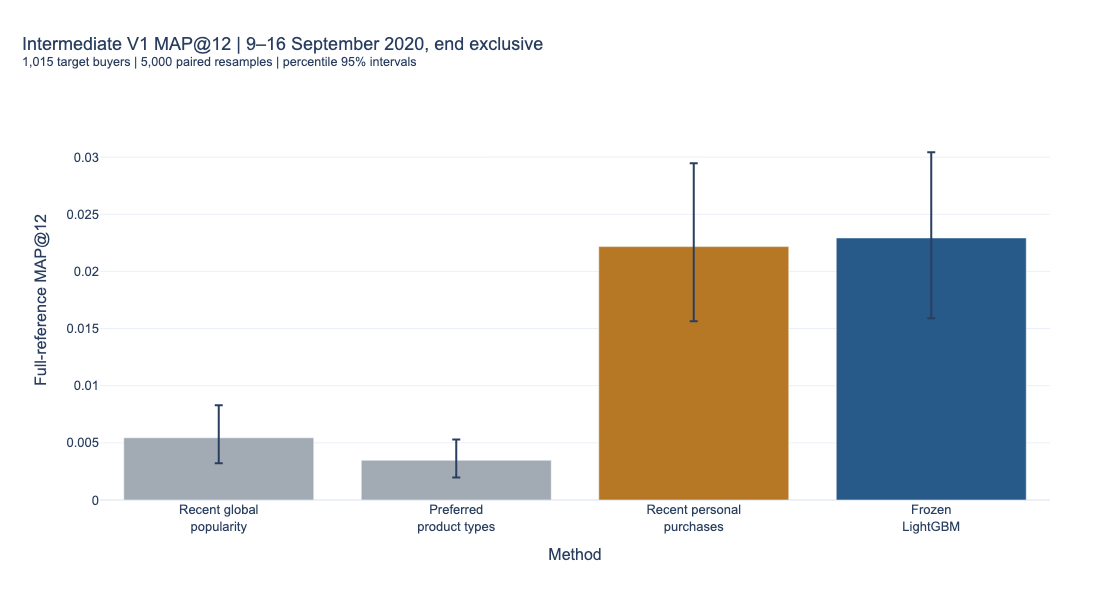

In [49]:
v1_map_intervals = v1_bootstrap_summary.loc[
    v1_bootstrap_summary["metric"].eq("map_at_12")
].copy()

v1_map_intervals["error_plus"] = (
    v1_map_intervals["ci_upper"] - v1_map_intervals["observed"]
)
v1_map_intervals["error_minus"] = (
    v1_map_intervals["observed"] - v1_map_intervals["ci_lower"]
)

assert v1_map_intervals[
    ["error_plus", "error_minus"]
].ge(0).all().all()

method_labels = {
    "recent_popularity_7d": "Recent global<br>popularity",
    "preferred_product_types": "Preferred<br>product types",
    "recent_purchases_180d": "Recent personal<br>purchases",
    frozen["method"]: "Frozen<br>LightGBM",
}
v1_map_intervals["method_label"] = (
    v1_map_intervals["method"].map(method_labels)
)

fig = px.bar(
    v1_map_intervals,
    x="method_label",
    y="observed",
    error_y="error_plus",
    error_y_minus="error_minus",
    hover_data=["ci_lower", "ci_upper", "evaluated_buyers"],
    labels={
        "method_label": "Method",
        "observed": "Full-reference MAP@12",
    },
    title=(
        "Intermediate V1 MAP@12 | 9–16 September 2020, end exclusive"
        f"<br><sup>{v1_n_buyers:,} target buyers | "
        "5,000 paired resamples | percentile 95% intervals</sup>"
    ),
)

fig.update_traces(
    marker_color=[
        "#285A89" if method == frozen["method"]
        else "#B67824" if method == v1_baseline
        else "#A2AAB3"
        for method in v1_map_intervals["method"]
    ]
)
fig.update_yaxes(
    range=[0, 1.15 * v1_map_intervals["ci_upper"].max()]
)

v1_figure_name = "v1_map_with_bootstrap_intervals"
show_figure(fig, PROJECT_ROOT, v1_figure_name, height=600)

In [50]:
evaluation_artifacts = []

for frame, name in [
    (v1_targets, "targets"),
    (v1_comparison, "comparison"),
    (v1_customer_scores, "customer_scores"),
    (v1_bootstrap_samples, "bootstrap_samples"),
    (v1_bootstrap_summary, "bootstrap_summary"),
]:
    path = V1_ROOT / f"{name}.csv"
    frame.to_csv(path, index=False)
    evaluation_artifacts.append(path)

evaluation_artifacts.append(
    PROJECT_ROOT / f"artifacts/figures/{v1_figure_name}.png"
)

v1_evaluation_manifest_path = V1_ROOT / "evaluation_manifest.json"

write_json(
    v1_evaluation_manifest_path,
    {
        "status": "complete",
        "start_inclusive": str(v1_start.date()),
        "end_exclusive": str(v1_end.date()),
        "prediction_manifest_sha256": file_sha256(
            V1_ROOT / "prediction_manifest.json"
        ),
        "model_sha256": prediction_manifest["model_sha256"],
        "selection_sha256": prediction_manifest["selection_sha256"],
        "recipients": len(v1_ids),
        "source_purchase_rows": len(v1_source_rows),
        "target_pairs": len(v1_targets),
        "target_buyers": v1_n_buyers,
        "excluded_nonbuyers": len(v1_ids) - v1_n_buyers,
        "baseline_comparator": v1_baseline,
        "bootstrap": {
            "unit": "target buyer",
            "paired": True,
            "resamples": V1_N_BOOTSTRAP,
            "seed": V1_BOOTSTRAP_SEED,
            "confidence_level": V1_CONFIDENCE_LEVEL,
            "interval_method": "percentile",
            "scope": "Fixed fitted systems and observed V1 week",
        },
        "prior_development_exposure": True,
        "confirmation_evaluated": False,
        "notebook_sha256": file_sha256(NOTEBOOK_PATH),
        "artifacts_sha256": {
            str(path.relative_to(PROJECT_ROOT)): file_sha256(path)
            for path in evaluation_artifacts
        },
    },
)

assert file_sha256(v1_model_path) == (
    prediction_manifest["model_sha256"]
)

model_manifest_path = DATA_ROOT / "final_ranker/manifest.json"
updated_model_manifest = json.loads(model_manifest_path.read_text())
updated_model_manifest["v1_evaluated"] = True
updated_model_manifest["v1_evaluation_manifest"] = str(
    v1_evaluation_manifest_path.relative_to(PROJECT_ROOT)
)
updated_model_manifest["v1_evaluation_manifest_sha256"] = (
    file_sha256(v1_evaluation_manifest_path)
)
write_json(model_manifest_path, updated_model_manifest)

selected_metrics = v1_comparison.set_index("method").loc[
    frozen["method"]
]
delta_summary = v1_bootstrap_summary.loc[
    v1_bootstrap_summary["method"].eq("model_minus_baseline")
].iloc[0]

with mlflow.start_run(run_id=v1_model_manifest["mlflow_run_id"]):
    for path in [
        *evaluation_artifacts,
        v1_evaluation_manifest_path,
    ]:
        mlflow.log_artifact(str(path), artifact_path="v1/evaluation")

    mlflow.log_artifact(
        str(model_manifest_path),
        artifact_path="final_refit/model",
    )
    mlflow.log_artifact(
        str(NOTEBOOK_PATH),
        artifact_path="v1/evaluation_source",
    )
    mlflow.log_metrics(
        {
            "v1_map_at_12": float(selected_metrics["map_at_k"]),
            "v1_recall_at_12": float(selected_metrics["recall_at_k"]),
            "v1_ndcg_at_12": float(selected_metrics["ndcg_at_k"]),
            "v1_delta_map": float(delta_summary["observed"]),
            "v1_delta_map_ci_lower": float(delta_summary["ci_lower"]),
            "v1_delta_map_ci_upper": float(delta_summary["ci_upper"]),
        }
    )

print("Intermediate V1 evaluation saved; final confirmation remains reserved.")

Intermediate V1 evaluation saved; final confirmation remains reserved.


## Stage-8 conclusion

The 63-leaf / minimum-20 configuration with all 31 features was selected
on complete-reference validation MAP@12. Gain importance, native SHAP,
declared ablations, errors, descriptive history segments, local timings
and paired customer bootstrap are recorded for the selected model.

After freezing eight boosting iterations, a new model was fitted on
seven weeks: 2,974 informative groups, 892,200 rows and 4,461 positives.
Save/reload scores agree on 1,000 probes.

On intermediate V1 [2020-09-09, 2020-09-16), 20,000 recipients receive
lists; target-based means cover 1,015 buyers and all 3,073 distinct targets.
LightGBM MAP@12 is 0.022927 versus 0.022168
for the validation-selected recent-purchases baseline.

The paired MAP difference is 0.000759, with percentile 95%
interval [-0.002626, 0.004346]. This does not establish
clear superiority or equivalence. Baseline Recall and NDCG are slightly
higher. No configuration was changed after V1 outcomes.

Candidate coverage is 618/3,073 (20.1106%). LightGBM retrieves 105 target
pairs versus 111. Catalogue coverage is 11.7976% versus 33.4577%, while
mean broad-group diversity is 3.33075 versus 2.70180 across all recipients.

V1 is retrospective because of prior development exposure. Bootstrap
conditions on fixed fitted systems and this week. Final confirmation
remains reserved for the later frozen LightGBM/PyTorch comparison.

The next reference-plan section is the reproducible local pipeline and
application. See the stage-8 evaluation report and model card.
